# 06 — Discrete-time hazard models

This notebook expands each Track A request into one row per year in the
queue, fits a multinomial logit and a LightGBM model of the yearly chance of
staying, reaching operation or withdrawing, and turns those hazards into
P(operation by 3, 5 and 7 years) and an expected time to operation for every
validation and test request. No test outcome is looked at here; scoring is
notebook 08's job, after its success criteria are written down.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 — every request, for the yearly congestion count |
| in | `data/interim/trackA.parquet` | notebook 04 — Track A requests with entry-time features and `entry_years` |
| in | `data/interim/predictions_05.parquet`, `results/cox_validation_calibration.csv` | notebook 05 — baseline and Cox predictions, 2016 check |
| out | `results/dt_rows_summary.csv`, `results/dt_life_table.csv`, `results/dt_queue_gw.csv` | project-year sample, yearly hazards, GW waiting over time |
| out | `results/dt_cv_logit.csv`, `results/dt_cv_lgbm.csv`, `results/dt_early_stopping.csv`, `results/dt_tuning.json` | grouped cross-validation and early stopping |
| out | `results/dt_validation_2016.csv` | 2016 cohort: mean predicted vs observed, four models, frozen vs realised congestion |
| out | `results/dt_logit_odds_ratios.csv`, `results/dt_lgbm_importance.csv`, `results/dt_reference_request.csv` | what the fitted models say |
| out | `results/dt_band_check.csv`, `results/dt_cohort_check.csv`, `results/dt_checks.csv` | acceptance checks (the band check is also `tests/test_discrete_time.py`) |
| out | `data/processed/predictions_trackA.parquet` | baseline, Cox, discrete-time logit and LightGBM P(operation by 3/5/7 yr) for validation and test requests |
| out | `figures/06_discrete_time_models/*.png|svg`, `report/figure_notes.md` | 17 figures |

## Setup

The model code is in `src/discrete_time.py`: `project_years` (rows with
delayed entry and yearly congestion), `prediction_rows` (years 1–10 as known
at entry), `encode_state` (state target encoding inside the training rows
only), `logit_design` / `lgbm_design`, `fit_logit` / `fit_lgbm` and
`cif_table` (hazards → P(operation by t) and expected time). The hazard →
incidence formula is `survival_tools.cif_from_hazards`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, features, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "06_discrete_time_models"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/06_discrete_time_models/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
YEARS = np.arange(1, discrete_time.MAX_YEARS + 1)
LOGIT_C = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]  # inverse ridge strength on standardised columns
LGBM_GRID = [{"num_leaves": leaves, "min_data_in_leaf": min_leaf} for leaves in [4, 8, 16, 32, 64] for min_leaf in [10, 20, 50]]
CV_ROUNDS = 1000  # LightGBM rounds recorded in each fold and on 2016 (learning rate 0.05)
OUTCOME_NAMES = {1: "operation", 2: "withdrawal"}
MODEL_LABELS = {"baseline": "Baseline", "cox": "Cox", "dt_logit": "Discrete-time logit", "dt_lgbm": "Discrete-time LightGBM"}
MODEL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"),
               "cox": dict(color="#555555", marker="D", linestyle=":"),
               "dt_logit": dict(color="#009E73", marker="o"),
               "dt_lgbm": dict(color="#CC79A7", marker="^")}

## 1. Samples and project-year rows

Tuning fits use entrants up to 2015, validation uses the 2016 entrants, the
final fits use entrants up to 2016, and predictions are made for the
2017–2019 test entrants — the same split as notebook 05. Each request becomes
one row per year in the queue (year k covers k − 1 to k years after the
request), up to year 10; the row of the year it leaves carries the outcome.

**Delayed entry in years.** ERCOT requests made before 2018-08-29 are watched
only from that day (decision #21). In a yearly model a year is kept only if
it starts on or after that day (`year − 1 ≥ entry_years`), so every row is a
full year (decision #26). The table below compares this with keeping the
year that *contains* the entry date.

In [2]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]

rows_tune = discrete_time.project_years(tune, clean)
rows_valid = discrete_time.project_years(valid, clean)
rows_final = discrete_time.project_years(final, clean)
print(f"project-years: tuning {len(rows_tune):,} | validation {len(rows_valid):,} | final {len(rows_final):,}")

by_region = rows_final.groupby("region")
summary = pd.DataFrame({
    "requests to 2016": final.groupby("region").size(),
    "requests with rows": by_region["project"].nunique(),
    "project-years": by_region.size(),
    "operations": rows_final[rows_final["outcome"] == 1].groupby("region").size(),
    "withdrawals": rows_final[rows_final["outcome"] == 2].groupby("region").size(),
}).reindex(TRACK_A)
summary.loc["all"] = summary.sum()
summary.to_csv(paths.RESULTS / "dt_rows_summary.csv")
summary

project-years: tuning 12,836 | validation 1,817 | final 14,653


,requests to 2016,requests with rows,project-years,operations,withdrawals
region,,,,,
ERCOT,732,98,288,36,33
PJM,3192,3192,10036,909,2198
CAISO,1374,1374,4329,171,1102
all,5298,4664,14653,1116,3333


In [3]:
# The alternative rule: keep the year that contains the entry date (after dropping requests that left before entry)
ercot = final[(final["region"] == "ERCOT") & (final["duration_years"] > final["entry_years"])]
partial = survival_tools.expand_project_years(ercot, max_years=discrete_time.MAX_YEARS)
partial = partial[partial["year_in_queue"].to_numpy() > ercot.loc[partial["project"], "entry_years"].to_numpy()]
first_kept = partial.groupby("project")["year_in_queue"].transform("min") == partial["year_in_queue"]
full = rows_final[rows_final["region"] == "ERCOT"]
rule_table = pd.DataFrame({
    "ERCOT project-years": [len(partial), len(full)],
    "of which partly watched": [int(first_kept.sum()), 0],
    "operation hazard": [(partial["outcome"] == 1).mean(), (full["outcome"] == 1).mean()],
    "withdrawal hazard": [(partial["outcome"] == 2).mean(), (full["outcome"] == 2).mean()],
}, index=["year containing entry kept", "full years only (used)"])
print("operation / withdrawal hazard in the partly watched years:",
      round((partial.loc[first_kept, "outcome"] == 1).mean(), 3), "/", round((partial.loc[first_kept, "outcome"] == 2).mean(), 3))
print("ERCOT rows by year in queue (used):", full["year_in_queue"].value_counts().sort_index().to_dict())
rule_table.round(3)

operation / withdrawal hazard in the partly watched years: 0.057 / 0.131
ERCOT rows by year in queue (used): {3: 24, 4: 40, 5: 52, 6: 54, 7: 45, 8: 35, 9: 23, 10: 15}


,ERCOT project-years,of which partly watched,operation hazard,withdrawal hazard
year containing entry kept,410,122,0.105,0.120
full years only (used),288,0,0.125,0.115


**Reading this.** The final fits use 14,653 project-years (tuning: 12,836 from entrants to 2015; validation: 1,817 from the 2016 entrants). PJM and CAISO contribute every request; ERCOT contributes only 98 of its 732 training requests, 288 project-years, 36 operations and 33 withdrawals, and is first seen in year 3 (24 rows). That is decision #21's cost, made slightly larger by the full-year rule of decision #26: keeping the year that contains 2018-08-29 would add 122 partly watched ERCOT years (410 instead of 288), but in those years the operation hazard is 0.057 against 0.125 in full years, because a project watched for a few months has fewer months in which to reach operation. Mixing the two would pull ERCOT's yearly hazards down. ERCOT's effect in this notebook therefore rests on a small sample, and its early years are borrowed from PJM and CAISO.

## 2. Yearly hazards in the data

Before any model: the share of requests still waiting at the start of year k
that reach operation, or withdraw, during year k (a life table), by region,
with 95% intervals. This is the shape the year-in-queue effects must
reproduce.

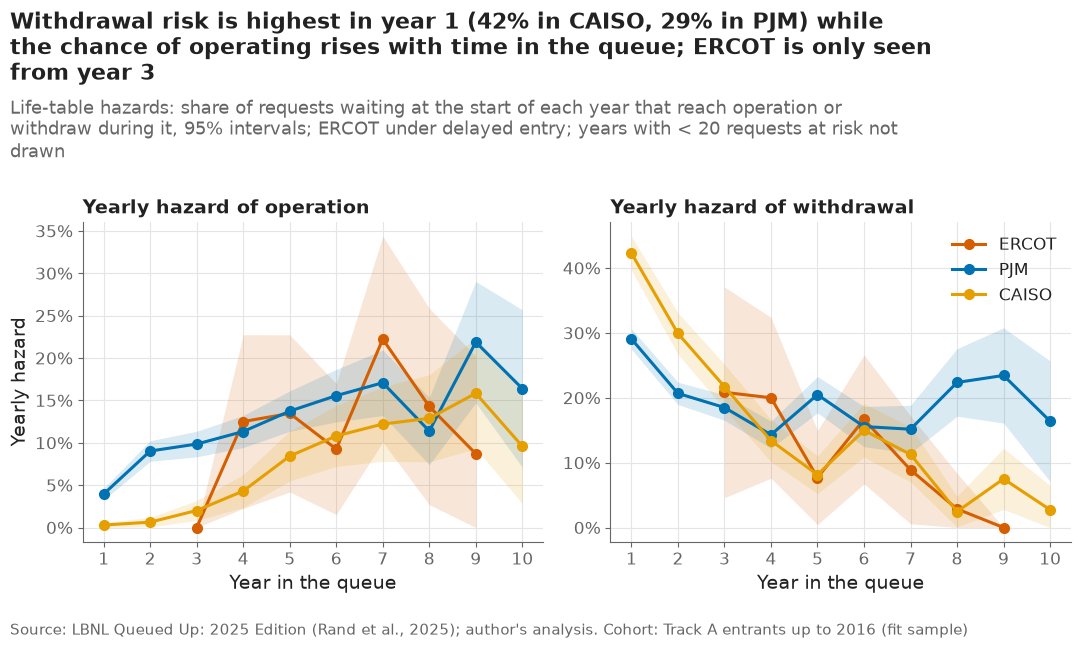

withdrawal hazard, years 1–3 pooled: {'CAISO': 0.345, 'ERCOT': 0.208, 'PJM': 0.241}


at_risk               h_operation               h_withdrawal              
region          CAISO ERCOT     PJM       CAISO  ERCOT    PJM        CAISO  ERCOT    PJM
year_in_queue                                                                           
1              1374.0   NaN  3192.0       0.003    NaN  0.039        0.423    NaN  0.291
2               789.0   NaN  2138.0       0.006    NaN  0.090        0.299    NaN  0.207
3               548.0  24.0  1503.0       0.020  0.000  0.098        0.217  0.208  0.185
4               418.0  40.0  1077.0       0.043  0.125  0.113        0.134  0.200  0.143
5               344.0  52.0   801.0       0.084  0.135  0.137        0.081  0.077  0.205
6               287.0  54.0   527.0       0.108  0.093  0.156        0.150  0.167  0.156
7               213.0  45.0   363.0       0.122  0.222  0.171        0.113  0.089  0.152
8               163.0  35.0   246.0       0.129  0.143  0.114        0.025  0.029  0.224
9               120.0  23.0   128.0       0.158  0.087  0.219        0.075  0.000  0.234
10               73.0  15.0    61.0       0.096  0.133  0.164        0.027  0.133  0.164

In [4]:
life = rows_final.groupby(["region", "year_in_queue"])["outcome"].agg(
    at_risk="size", h_operation=lambda s: (s == 1).mean(), h_withdrawal=lambda s: (s == 2).mean()).reset_index()
life.to_csv(paths.RESULTS / "dt_life_table.csv", index=False)

fig, axes = plt.subplots(1, 2, sharex=True)
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    for region in TRACK_A:
        part = life[(life["region"] == region) & (life["at_risk"] >= 20)]
        h = part[f"h_{cause}"]
        se = np.sqrt(h * (1 - h) / part["at_risk"])
        ax.fill_between(part["year_in_queue"], (h - 1.96 * se).clip(lower=0), h + 1.96 * se,
                        color=plots.region_color(region), alpha=0.15, linewidth=0)
        ax.plot(part["year_in_queue"], h, color=plots.region_color(region), marker="o", label=region)
    ax.set_title(f"Yearly hazard of {cause}")
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Yearly hazard")
axes[1].legend(loc="upper right")
early_wd = life[life["year_in_queue"] <= 3].groupby("region").apply(
    lambda p: (p["h_withdrawal"] * p["at_risk"]).sum() / p["at_risk"].sum(), include_groups=False)
year1 = life[life["year_in_queue"] == 1].set_index("region")
plots.finish(fig,
             f"Withdrawal risk is highest in year 1 ({year1.loc['CAISO', 'h_withdrawal']:.0%} in CAISO, "
             f"{year1.loc['PJM', 'h_withdrawal']:.0%} in PJM) while the chance of operating rises with time in the queue; "
             f"ERCOT is only seen from year {int(life.loc[life['region'] == 'ERCOT', 'year_in_queue'].min())}",
             "Life-table hazards: share of requests waiting at the start of each year that reach operation or withdraw "
             "during it, 95% intervals; ERCOT under delayed entry; years with < 20 requests at risk not drawn",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR} (fit sample)")
save(fig, "06_01_life_table_hazards", "Yearly hazards of operation and withdrawal by year in the queue and region (life table of the fit sample).")
plt.show()
print("withdrawal hazard, years 1–3 pooled:", early_wd.round(3).to_dict())
life.pivot_table(index="year_in_queue", columns="region", values=["at_risk", "h_operation", "h_withdrawal"]).round(3)

**Reading this.** Withdrawal is the dominant exit early: in year 1, 42.3% of waiting CAISO requests and 29.1% of PJM requests withdraw (years 1–3 pooled: 34.5% and 24.1%; ERCOT's year 3, the first it is seen, 20.8%). The operation hazard starts near zero (0.3% in CAISO's first year, 3.9% in PJM's) and climbs to 17.1% (PJM) and 12.2% (CAISO) by year 7. So the two exits have opposite shapes over the wait — exactly what a single proportional hazard ratio cannot represent and why every year gets its own effect here. PJM's withdrawal hazard stays high in years 8 and 9 (22.4% and 23.4%), probably including the 2024-12-18 withdrawal cluster kept as recorded (decision #23). ERCOT's points rest on 15–54 requests per year, hence the wide intervals.

## 3. Time-varying congestion

Congestion at entry (notebook 04) is a snapshot. Here it is recounted on the
first day of every project-year: GW of same-region requests that entered
before that day and had not left, minus the project itself. First the
queues themselves over calendar time; then how far a project's congestion in
year k drifts from its value at entry — which matters because a prediction
made at entry must hold congestion at its entry value (section 7 measures
the cost).

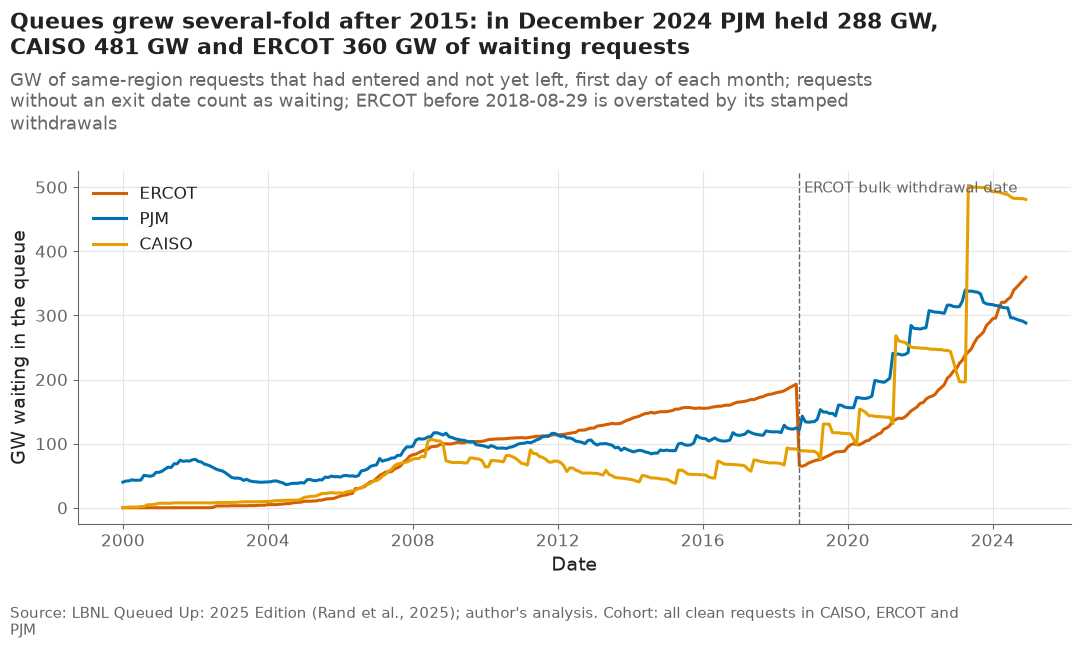

,ERCOT,PJM,CAISO
date,,,
2005-01-01,10.0,39.0,16.0
2010-01-01,105.0,96.0,64.0
2015-01-01,150.0,90.0,45.0
2018-01-01,179.0,119.0,70.0
2020-01-01,95.0,156.0,116.0
2024-01-01,295.0,317.0,493.0
2024-12-01,360.0,288.0,481.0


In [5]:
months = pd.date_range("2000-01-01", config.CENSOR_DATE, freq="MS")
queue_gw = pd.DataFrame({region: features.congestion_on_dates(clean, [region] * len(months), months)["congestion_gw"].to_numpy()
                         for region in TRACK_A}, index=months)
queue_gw.index.name = "date"
queue_gw.to_csv(paths.RESULTS / "dt_queue_gw.csv")

fig, ax = plt.subplots()
for region in TRACK_A:
    ax.plot(queue_gw.index, queue_gw[region], color=plots.region_color(region), label=region)
stamp = pd.Timestamp(config.ERCOT_BULK_WD_DATE)
ax.axvline(stamp, color=plots.MUTED, linewidth=1, linestyle="--")
ax.text(stamp, ax.get_ylim()[1] * 0.97, " ERCOT bulk withdrawal date", fontsize=11, color=plots.MUTED, va="top")
ax.set_xlabel("Date")
ax.set_ylabel("GW waiting in the queue")
ax.legend(loc="upper left")
snap = queue_gw.loc[[pd.Timestamp(f"{y}-01-01") for y in [2005, 2010, 2015, 2018, 2020, 2024]] + [queue_gw.index[-1]]]
end = queue_gw.iloc[-1]
plots.finish(fig,
             f"Queues grew several-fold after 2015: in {queue_gw.index[-1]:%B %Y} PJM held {end['PJM']:.0f} GW, CAISO "
             f"{end['CAISO']:.0f} GW and ERCOT {end['ERCOT']:.0f} GW of waiting requests",
             "GW of same-region requests that had entered and not yet left, first day of each month; requests without an "
             "exit date count as waiting; ERCOT before 2018-08-29 is overstated by its stamped withdrawals",
             "all clean requests in CAISO, ERCOT and PJM")
save(fig, "06_02_queue_gw_over_time", "GW waiting in each Track A queue, monthly, 2000–2024.")
plt.show()
snap.round(0)

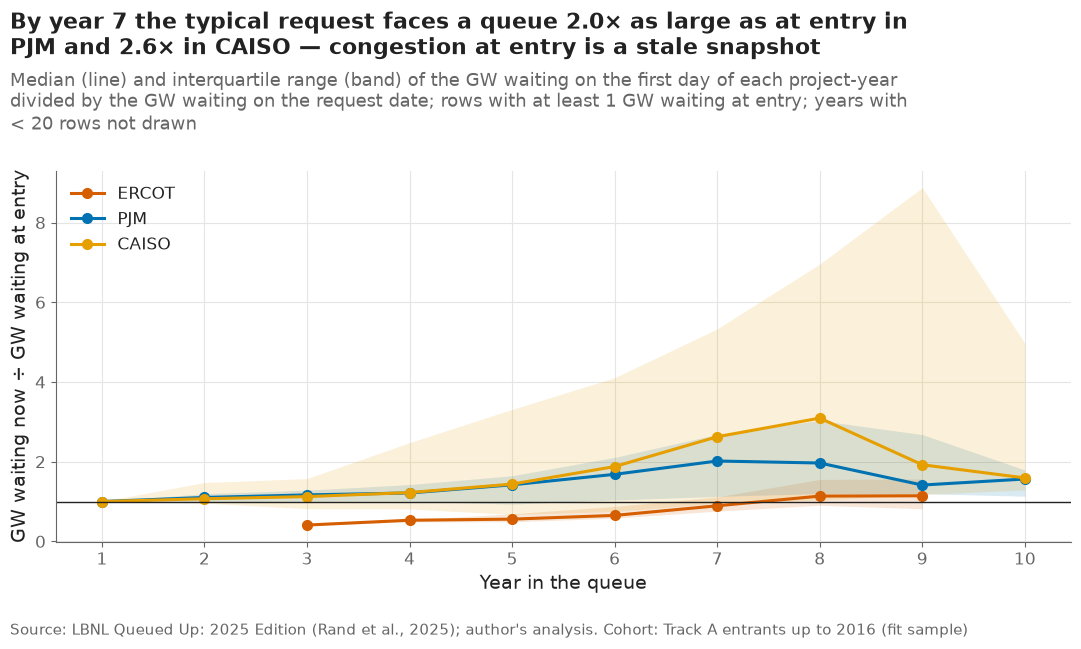

region,CAISO,ERCOT,PJM
year_in_queue,,,
1,1.00,NaN,1.00
2,1.07,NaN,1.10
3,1.12,0.41,1.17
4,1.22,0.53,1.21
5,1.44,0.56,1.42
6,1.88,0.65,1.68
7,2.63,0.89,2.02
8,3.09,1.14,1.97
9,1.92,1.14,1.41


In [6]:
entry_gw = final.loc[rows_final["project"], "congestion_gw"].to_numpy()
drift = rows_final.assign(entry_gw=entry_gw)
drift = drift[drift["entry_gw"] >= 1]  # ratios are meaningless when almost nothing was waiting at entry
drift["ratio"] = drift["congestion_gw"] / drift["entry_gw"]
drift_table = drift.groupby(["region", "year_in_queue"])["ratio"].quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots()
for region in TRACK_A:
    part = drift_table.loc[region]
    part = part[drift.groupby(["region", "year_in_queue"]).size().loc[region] >= 20]
    ax.fill_between(part.index, part[0.25], part[0.75], color=plots.region_color(region), alpha=0.15, linewidth=0)
    ax.plot(part.index, part[0.5], color=plots.region_color(region), marker="o", label=region)
ax.axhline(1, color=plots.INK, linewidth=1)
ax.set_xlabel("Year in the queue")
ax.set_ylabel("GW waiting now ÷ GW waiting at entry")
ax.set_xticks(YEARS)
ax.legend(loc="upper left")
med = drift_table[0.5]
plots.finish(fig,
             f"By year 7 the typical request faces a queue {med.loc[('PJM', 7)]:.1f}× as large as at entry in PJM and "
             f"{med.loc[('CAISO', 7)]:.1f}× in CAISO — congestion at entry is a stale snapshot",
             "Median (line) and interquartile range (band) of the GW waiting on the first day of each project-year divided "
             "by the GW waiting on the request date; rows with at least 1 GW waiting at entry; years with < 20 rows not drawn",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR} (fit sample)")
save(fig, "06_03_congestion_drift", "Ratio of yearly congestion to congestion at entry, by year in the queue and region.")
plt.show()
med.unstack("region").round(2)

**Reading this.** The queues these projects wait in changed a lot while they waited. PJM held 90 GW of waiting requests on 2015-01-01, 317 GW on 2024-01-01 and 288 GW in December 2024; CAISO went from 45 GW to 493 GW and 481 GW. ERCOT's line before 2018-08-29 is not real (its stamped withdrawals count as waiting until that day, then drop out at once), which is also why ERCOT's ratio in the second chart sits below 1: its entry congestion is overstated. For PJM and CAISO, the median request faces 1.4× its entry congestion by year 5 (1.42 and 1.44) and 2.0× and 2.6× by year 7. A prediction made at entry cannot know this, so predictions hold congestion at its entry value; section 7 measures what that costs.

## 4. Grouped cross-validation: the multinomial logit

Five folds on the tuning rows (entrants to 2015), **grouped by project** so
that no request has years in both the fitting and the scoring part. Inside
each fold the state is target-encoded on the fitting part only (its own rows
out of fold), then the logit is fitted for each ridge strength C, with and
without the "early" interactions (CAISO, technology and size in years 1–3,
the drift notebook 05 found). Score: mean log loss of the observed outcome
of each held-out project-year (lower is better).

projects shared between a fold's fitting and scoring parts: 0


no-information log loss (class shares only): 0.7923
chosen: interactions=True, C=0.1, CV log loss 0.7195


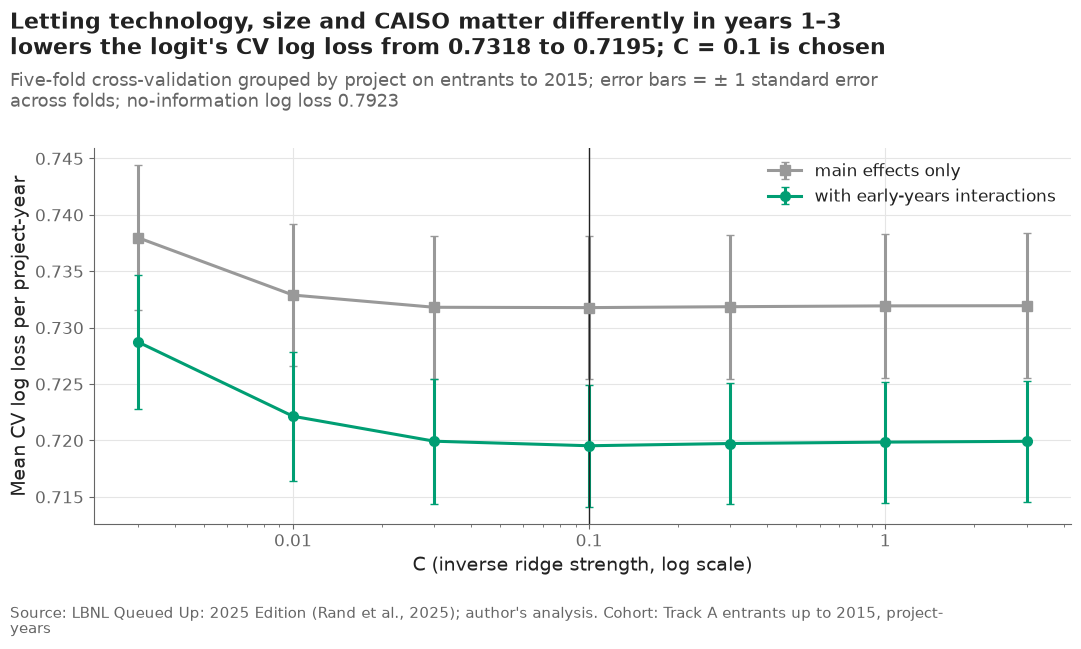

interactions,False,True
C,,
0.003,0.7380,0.7287
0.010,0.7329,0.7221
0.030,0.7318,0.7199
0.100,0.7318,0.7195
0.300,0.7319,0.7197
1.000,0.7319,0.7199
3.000,0.7319,0.7199


In [7]:
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=0).split(rows_tune, groups=rows_tune["project"]))
overlap = sum(len(set(rows_tune["project"].iloc[a]) & set(rows_tune["project"].iloc[b])) for a, b in folds)
print("projects shared between a fold's fitting and scoring parts:", overlap)
fold_data = [discrete_time.encode_state(rows_tune.iloc[fit_idx], [rows_tune.iloc[held_idx]]) for fit_idx, held_idx in folds]
null_loss = np.mean([discrete_time.multiclass_log_loss(
    held["outcome"], np.tile(np.bincount(fit["outcome"], minlength=3) / len(fit), (len(held), 1))) for fit, held in fold_data])

logit_rows = []
for interactions in [False, True]:
    for C in LOGIT_C:
        for i, (fit_rows, held_rows) in enumerate(fold_data):
            model = discrete_time.fit_logit(discrete_time.logit_design(fit_rows, interactions), fit_rows["outcome"], C)
            probs = model.predict_proba(discrete_time.logit_design(held_rows, interactions))
            logit_rows.append({"interactions": interactions, "C": C, "fold": i,
                               "log_loss": discrete_time.multiclass_log_loss(held_rows["outcome"], probs)})
logit_cv = pd.DataFrame(logit_rows)
logit_cv.to_csv(paths.RESULTS / "dt_cv_logit.csv", index=False)
logit_mean = logit_cv.groupby(["interactions", "C"])["log_loss"].agg(["mean", "std"]).reset_index()
best_logit = logit_mean.loc[logit_mean["mean"].idxmin()]
INTERACTIONS, LOGIT_BEST_C = bool(best_logit["interactions"]), float(best_logit["C"])
print(f"no-information log loss (class shares only): {null_loss:.4f}")
print(f"chosen: interactions={INTERACTIONS}, C={LOGIT_BEST_C:g}, CV log loss {best_logit['mean']:.4f}")

fig, ax = plt.subplots()
for interactions, style in [(False, dict(color="#999999", marker="s")), (True, dict(color="#009E73", marker="o"))]:
    part = logit_mean[logit_mean["interactions"] == interactions]
    ax.errorbar(part["C"], part["mean"], yerr=part["std"] / np.sqrt(len(folds)), capsize=3,
                label="with early-years interactions" if interactions else "main effects only", **style)
ax.axvline(LOGIT_BEST_C, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("C (inverse ridge strength, log scale)")
ax.set_ylabel("Mean CV log loss per project-year")
ax.legend(loc="upper right")
plain = logit_mean[~logit_mean["interactions"]]["mean"].min()
plots.finish(fig,
             f"Letting technology, size and CAISO matter differently in years 1–3 lowers the logit's CV log loss from "
             f"{plain:.4f} to {logit_mean[logit_mean['interactions']]['mean'].min():.4f}; C = {LOGIT_BEST_C:g} is chosen",
             f"Five-fold cross-validation grouped by project on entrants to {config.TUNE_MAX_YEAR}; error bars = ± 1 standard "
             f"error across folds; no-information log loss {null_loss:.4f}",
             f"Track A entrants up to {config.TUNE_MAX_YEAR}, project-years")
save(fig, "06_04_logit_cv", "Grouped cross-validation log loss of the multinomial logit by ridge strength, with and without early-years interactions.")
plt.show()
logit_mean.pivot(index="C", columns="interactions", values="mean").round(4)

**Reading this.** Every logit beats the no-information log loss of 0.7923 by a wide margin. Letting CAISO, technology and size have separate effects in years 1–3 lowers the cross-validated log loss from 0.7318 to 0.7195 — a larger gain than any change in the penalty, and the same direction as notebook 05's Schoenfeld diagnostics. The penalty barely matters once it is not very strong (0.7195–0.7199 for C between 0.03 and 3), so C = 0.1 with interactions is a stable choice, not a knife-edge one.

## 5. Grouped cross-validation: LightGBM

The same folds and the same encoded states. For each of 15 tree settings
(leaves per tree × minimum rows per leaf) LightGBM is run for 1,000 rounds and
the held-out log loss is recorded after every round. The plan was to choose
the setting here; section 6 explains why the choice is made on the 2016
cohort instead (decision #27), and this section keeps the cross-validation
as the evidence for that.

best in cross-validation: 64 leaves, min. 10 rows per leaf, 109 rounds, CV log loss 0.6591 (logit: 0.7195, no information: 0.7923)


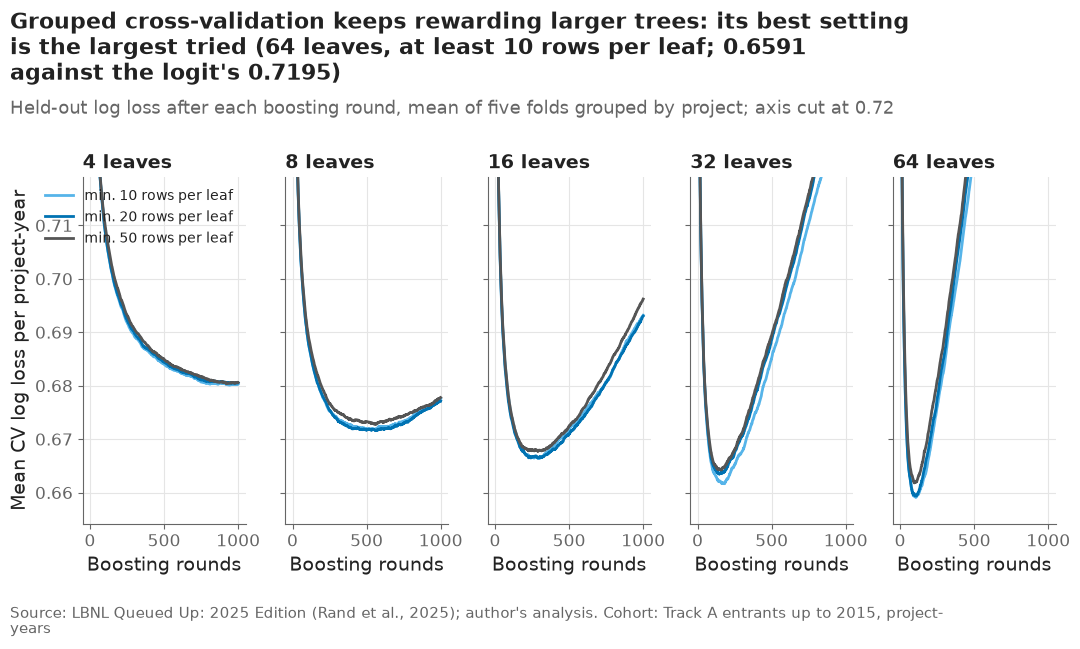

,num_leaves,min_data_in_leaf,cv_rounds,cv_log_loss
12,64,10,109,0.6591
13,64,20,110,0.6594
9,32,10,180,0.6617
14,64,50,96,0.6618
10,32,20,146,0.6634
11,32,50,160,0.6642
6,16,10,295,0.6664
7,16,20,242,0.6665
8,16,50,292,0.6678
4,8,20,561,0.6716


In [8]:
curves, boosters = {}, {}
for params in LGBM_GRID:
    key = (params["num_leaves"], params["min_data_in_leaf"])
    fold_curves = []
    for i, (fit_rows, held_rows) in enumerate(fold_data):
        record = {}
        boosters[(key, i)] = discrete_time.fit_lgbm(
            discrete_time.lgbm_design(fit_rows), fit_rows["outcome"], params, CV_ROUNDS,
            valid=(discrete_time.lgbm_design(held_rows), held_rows["outcome"]), record=record)
        fold_curves.append(record["valid"]["multi_logloss"])
    curves[key] = np.mean(fold_curves, axis=0)
lgbm_cv = pd.DataFrame([{"num_leaves": k[0], "min_data_in_leaf": k[1], "cv_rounds": int(c.argmin() + 1),
                         "cv_log_loss": float(c.min())} for k, c in curves.items()])
cv_best = lgbm_cv.loc[lgbm_cv["cv_log_loss"].idxmin()]
print(f"best in cross-validation: {int(cv_best['num_leaves'])} leaves, min. {int(cv_best['min_data_in_leaf'])} rows per "
      f"leaf, {int(cv_best['cv_rounds'])} rounds, CV log loss {cv_best['cv_log_loss']:.4f} "
      f"(logit: {best_logit['mean']:.4f}, no information: {null_loss:.4f})")

fig, axes = plt.subplots(1, 5, sharey=True)
shades = {10: "#56B4E9", 20: "#0072B2", 50: "#555555"}
for ax, leaves in zip(axes, [4, 8, 16, 32, 64]):
    for min_leaf, color in shades.items():
        ax.plot(np.arange(1, CV_ROUNDS + 1), curves[(leaves, min_leaf)], color=color, linewidth=2,
                label=f"min. {min_leaf} rows per leaf")
    ax.set_title(f"{leaves} leaves")
    ax.set_xlabel("Boosting rounds")
ax_low = min(c.min() for c in curves.values())
axes[0].set_ylim(ax_low - 0.005, ax_low + 0.06)
axes[0].set_ylabel("Mean CV log loss per project-year")
axes[0].legend(loc="upper right", fontsize=10)
plots.finish(fig,
             f"Grouped cross-validation keeps rewarding larger trees: its best setting is the largest tried "
             f"({int(cv_best['num_leaves'])} leaves, at least {int(cv_best['min_data_in_leaf'])} rows per leaf; "
             f"{cv_best['cv_log_loss']:.4f} against the logit's {best_logit['mean']:.4f})",
             f"Held-out log loss after each boosting round, mean of five folds grouped by project; axis cut at "
             f"{ax_low + 0.06:.2f}",
             f"Track A entrants up to {config.TUNE_MAX_YEAR}, project-years")
save(fig, "06_05_lgbm_cv", "Grouped cross-validation log loss of LightGBM by boosting round for 15 tree settings.")
plt.show()
lgbm_cv.sort_values("cv_log_loss").round(4)

**Reading this.** In grouped cross-validation every LightGBM setting beats the logit (0.6591–0.6805 against 0.7195), and the larger the trees the better: the best setting is the largest tried, 64 leaves with at least 10 rows per leaf (0.6591 after 109 rounds) — again at the edge of the grid, as in a first, smaller grid that stopped at 32 leaves. A search that always ends at its own edge is a warning sign rather than an answer. Folds are grouped by project, but all folds share the same calendar years, so a tree can learn "what happened to everybody in year X" from the fitting folds and be rewarded for it in the scoring fold. Such events do not carry forward to later entrants. Section 6 tests this on the 2016 cohort.

## 6. Choosing LightGBM on the 2016 cohort (early stopping)

Every tree setting is fitted on all tuning rows (entrants to 2015) and
watched on the project-years of the 2016 entrants, which lie ahead in time.
The setting and the number of rounds with the lowest 2016 log loss are kept
for the final refit — the same use of the 2016 cohort as the Cox penalty in
notebook 05. Grouped folds keep a project's years together but not a
calendar year's: projects in different folds share the same years in the
queue's history, so cross-validation can reward trees that learn year-
specific events that do not carry forward. The chosen logit is scored on the
same rows for comparison.

chosen on 2016: {'num_leaves': 8, 'min_data_in_leaf': 10}, 331 rounds, 2016 log loss 0.6493; the CV's choice scores 0.6658 on 2016
Spearman correlation of the 15 settings' CV and 2016 log losses: -0.65


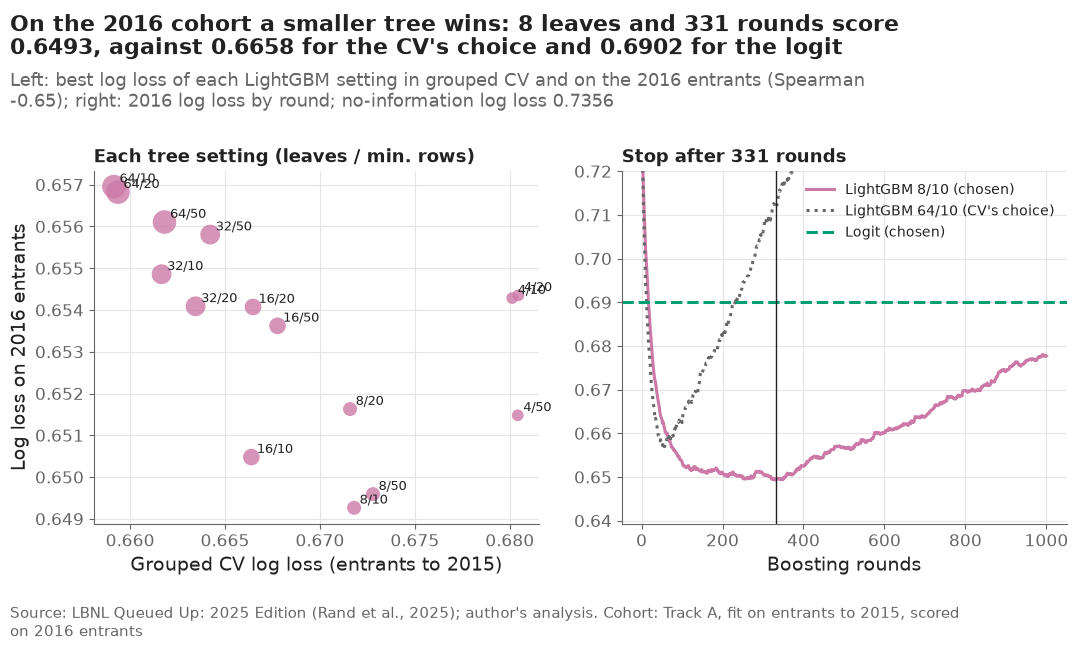

no information              0.7356
dt_logit                    0.6902
dt_lgbm (chosen on 2016)    0.6493
dt_lgbm (CV's choice)       0.6658
dtype: float64

In [9]:
tune_enc, valid_enc = discrete_time.encode_state(rows_tune, [rows_valid])
valid_curves = {}
for params in LGBM_GRID:
    record = {}
    discrete_time.fit_lgbm(discrete_time.lgbm_design(tune_enc), tune_enc["outcome"], params, CV_ROUNDS,
                           valid=(discrete_time.lgbm_design(valid_enc), valid_enc["outcome"]), record=record)
    valid_curves[(params["num_leaves"], params["min_data_in_leaf"])] = np.array(record["valid"]["multi_logloss"])
lgbm_cv["valid_rounds"] = [int(valid_curves[(r.num_leaves, r.min_data_in_leaf)].argmin() + 1) for r in lgbm_cv.itertuples()]
lgbm_cv["valid_log_loss"] = [float(valid_curves[(r.num_leaves, r.min_data_in_leaf)].min()) for r in lgbm_cv.itertuples()]
lgbm_cv.to_csv(paths.RESULTS / "dt_cv_lgbm.csv", index=False)
chosen = lgbm_cv.loc[lgbm_cv["valid_log_loss"].idxmin()]
LGBM_PARAMS = {"num_leaves": int(chosen["num_leaves"]), "min_data_in_leaf": int(chosen["min_data_in_leaf"])}
N_ROUNDS = int(chosen["valid_rounds"])
CHOSEN_CV_ROUNDS = int(chosen["cv_rounds"])
es_curve = valid_curves[(LGBM_PARAMS["num_leaves"], LGBM_PARAMS["min_data_in_leaf"])]
pd.DataFrame({"round": np.arange(1, CV_ROUNDS + 1), "valid_log_loss": es_curve}).to_csv(
    paths.RESULTS / "dt_early_stopping.csv", index=False)
cv_on_2016 = float(valid_curves[(int(cv_best["num_leaves"]), int(cv_best["min_data_in_leaf"]))][int(cv_best["cv_rounds"]) - 1])
rank_agreement = lgbm_cv[["cv_log_loss", "valid_log_loss"]].corr(method="spearman").iloc[0, 1]
print(f"chosen on 2016: {LGBM_PARAMS}, {N_ROUNDS} rounds, 2016 log loss {chosen['valid_log_loss']:.4f}; "
      f"the CV's choice scores {cv_on_2016:.4f} on 2016")
print(f"Spearman correlation of the 15 settings' CV and 2016 log losses: {rank_agreement:.2f}")

logit_tune = discrete_time.fit_logit(discrete_time.logit_design(tune_enc, INTERACTIONS), tune_enc["outcome"], LOGIT_BEST_C)
lgbm_tune = discrete_time.fit_lgbm(discrete_time.lgbm_design(tune_enc), tune_enc["outcome"], LGBM_PARAMS, N_ROUNDS)
valid_loss = {
    "no information": discrete_time.multiclass_log_loss(
        valid_enc["outcome"], np.tile(np.bincount(tune_enc["outcome"], minlength=3) / len(tune_enc), (len(valid_enc), 1))),
    "dt_logit": discrete_time.multiclass_log_loss(
        valid_enc["outcome"], logit_tune.predict_proba(discrete_time.logit_design(valid_enc, INTERACTIONS))),
    "dt_lgbm (chosen on 2016)": float(chosen["valid_log_loss"]),
    "dt_lgbm (CV's choice)": cv_on_2016,
}
tuning = {"logit": {"interactions": INTERACTIONS, "C": LOGIT_BEST_C, "cv_log_loss": float(best_logit["mean"])},
          "lgbm": {**LGBM_PARAMS, "rounds": N_ROUNDS, "valid_log_loss": float(chosen["valid_log_loss"]),
                   "cv_log_loss_of_this_setting": float(chosen["cv_log_loss"]),
                   "cv_choice": {"num_leaves": int(cv_best["num_leaves"]),
                                 "min_data_in_leaf": int(cv_best["min_data_in_leaf"]),
                                 "rounds": int(cv_best["cv_rounds"]), "cv_log_loss": float(cv_best["cv_log_loss"])}},
          "validation_log_loss_2016": valid_loss}
(paths.RESULTS / "dt_tuning.json").write_text(json.dumps(tuning, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2)
ax = axes[0]
ax.scatter(lgbm_cv["cv_log_loss"], lgbm_cv["valid_log_loss"], s=12 * np.sqrt(lgbm_cv["num_leaves"]) * 3,
           color=MODEL_STYLE["dt_lgbm"]["color"], alpha=0.8, edgecolors="white")
for r in lgbm_cv.itertuples():
    ax.annotate(f"{r.num_leaves}/{r.min_data_in_leaf}", (r.cv_log_loss, r.valid_log_loss), xytext=(4, 3),
                textcoords="offset points", fontsize=9)
ax.set_xlabel("Grouped CV log loss (entrants to 2015)")
ax.set_ylabel("Log loss on 2016 entrants")
ax.set_title("Each tree setting (leaves / min. rows)", fontsize=13)
ax = axes[1]
ax.plot(np.arange(1, CV_ROUNDS + 1), es_curve, color=MODEL_STYLE["dt_lgbm"]["color"],
        label=f"LightGBM {LGBM_PARAMS['num_leaves']}/{LGBM_PARAMS['min_data_in_leaf']} (chosen)")
cv_curve = valid_curves[(int(cv_best["num_leaves"]), int(cv_best["min_data_in_leaf"]))]
ax.plot(np.arange(1, CV_ROUNDS + 1), cv_curve, color=plots.MUTED, linestyle=":",
        label=f"LightGBM {int(cv_best['num_leaves'])}/{int(cv_best['min_data_in_leaf'])} (CV's choice)")
ax.axhline(valid_loss["dt_logit"], color=MODEL_STYLE["dt_logit"]["color"], linestyle="--", label="Logit (chosen)")
ax.axvline(N_ROUNDS, color=plots.INK, linewidth=1)
ax.set_ylim(es_curve.min() - 0.01, valid_loss["dt_logit"] + 0.03)
ax.set_xlabel("Boosting rounds")
ax.set_title(f"Stop after {N_ROUNDS} rounds", fontsize=13)
ax.legend(loc="upper right", fontsize=10)
plots.finish(fig,
             f"On the 2016 cohort {'a smaller tree wins' if LGBM_PARAMS['num_leaves'] < cv_best['num_leaves'] else 'the ranking holds'}: "
             f"{LGBM_PARAMS['num_leaves']} leaves and {N_ROUNDS} rounds score "
             f"{chosen['valid_log_loss']:.4f}, against {cv_on_2016:.4f} for the CV's choice and {valid_loss['dt_logit']:.4f} "
             f"for the logit",
             f"Left: best log loss of each LightGBM setting in grouped CV and on the 2016 entrants (Spearman {rank_agreement:.2f}); "
             f"right: 2016 log loss by round; no-information log loss {valid_loss['no information']:.4f}",
             f"Track A, fit on entrants to {config.TUNE_MAX_YEAR}, scored on 2016 entrants")
save(fig, "06_06_early_stopping", "LightGBM tree settings scored in grouped cross-validation and on the 2016 cohort, and the 2016 log loss by round.")
plt.show()
pd.Series(valid_loss).round(4)

**Reading this.** On the 2016 entrants — later in time than every fitting row — the ranking of the 15 settings is close to reversed (Spearman −0.65 between their CV and 2016 log losses). The CV's choice (64 leaves) scores 0.6658 on 2016, while 8 leaves with at least 10 rows per leaf, stopped after 331 rounds, scores 0.6493, the best of the grid; the logit scores 0.6902 and no information 0.7356. Following the plan literally would have picked the setting that generalises worst forward in time. LightGBM's setting and round count are therefore chosen on the 2016 cohort (decision #27), as notebook 05 chose the Cox penalty, and the cross-validation is kept as the evidence. The cost is that the 2016 cohort is no longer fully independent for LightGBM: the section 7 check on it is partly in-sample for the round count and setting.

## 7. A check on the 2016 cohort: predicted vs observed incidence

Log loss per project-year says which model ranks hazards better; what a
developer sees is P(operation by t). The tuning fits (entrants to 2015)
predict each 2016 request from its entry date, **with congestion frozen at
its entry value**, and the mean prediction per region is set against the
observed Aalen–Johansen estimate and its 95% bootstrap band. The baseline
and Cox numbers are notebook 05's (also fitted on entrants to 2015).

mean absolute error of the mean prediction, points (9 region × horizon cells): {'baseline': 2.6, 'cox': 3.9, 'dt_logit': 1.8, 'dt_lgbm': 1.7, 'dt_logit_realised': 1.9, 'dt_lgbm_realised': 2.5}


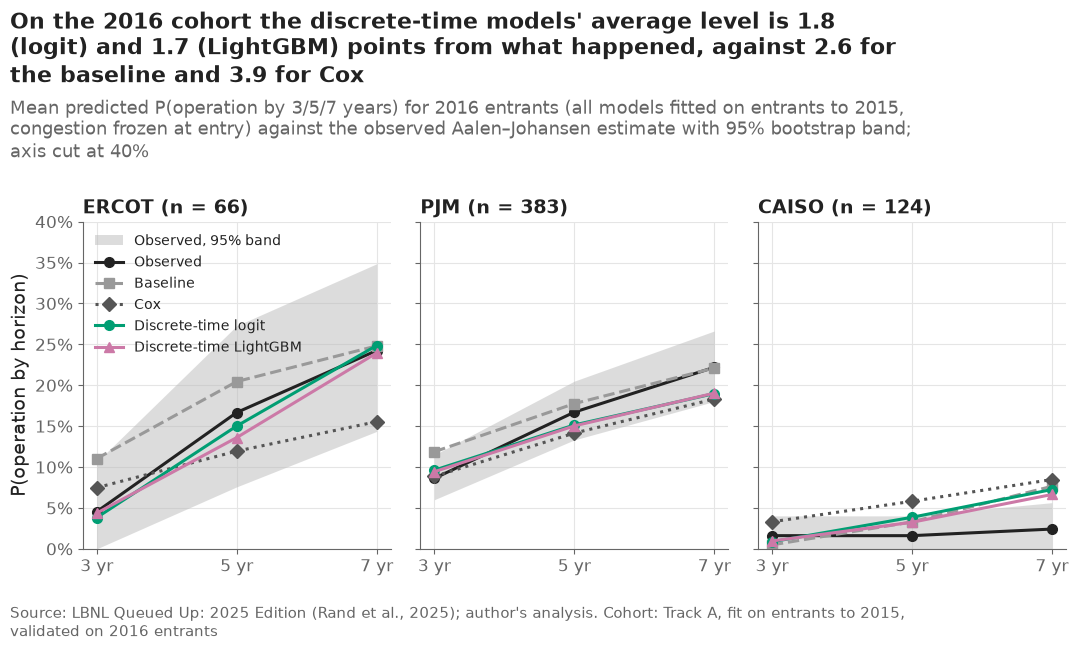

,region,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,ERCOT,3,0.045,0.000,0.106,0.110,0.075,0.038,0.044
1,ERCOT,5,0.167,0.076,0.273,0.205,0.119,0.150,0.136
2,ERCOT,7,0.242,0.144,0.348,0.248,0.155,0.249,0.239
3,PJM,3,0.086,0.060,0.115,0.119,0.089,0.096,0.094
4,PJM,5,0.167,0.133,0.205,0.178,0.141,0.151,0.150
5,PJM,7,0.222,0.180,0.266,0.221,0.183,0.190,0.190
6,CAISO,3,0.016,0.000,0.040,0.005,0.033,0.009,0.010
7,CAISO,5,0.016,0.000,0.040,0.033,0.058,0.039,0.032
8,CAISO,7,0.024,0.000,0.056,0.076,0.085,0.072,0.066


In [10]:
def predict(frame, fit_rows, logit_model, lgbm_model, horizons=HORIZONS, realised=False):
    """P(operation by each horizon) and expected time from both discrete-time models, as known at entry."""
    rows = discrete_time.prediction_rows(frame)
    if realised:  # diagnostic only: the queue as it actually turned out, which is not known at entry
        rows["congestion_gw"] = discrete_time.yearly_congestion(rows, frame, clean)
        rows["log_congestion_gw"] = np.log1p(rows["congestion_gw"])
    _, rows = discrete_time.encode_state(fit_rows, [rows])
    return {
        "dt_logit": discrete_time.cif_table(*discrete_time.predict_hazards(
            logit_model, discrete_time.logit_design(rows, INTERACTIONS)), frame.index, horizons),
        "dt_lgbm": discrete_time.cif_table(*discrete_time.predict_hazards(
            lgbm_model, discrete_time.lgbm_design(rows)), frame.index, horizons),
    }


valid_frozen = predict(valid, rows_tune, logit_tune, lgbm_tune)
valid_realised = predict(valid, rows_tune, logit_tune, lgbm_tune, realised=True)
check05 = pd.read_csv(paths.RESULTS / "cox_validation_calibration.csv")
val_rows = []
for _, row in check05.iterrows():
    index = valid.index[valid["region"] == row["region"]]
    entry = row.to_dict()
    for model in ["dt_logit", "dt_lgbm"]:
        entry[model] = valid_frozen[model].loc[index, row["horizon"]].mean()
        entry[f"{model}_realised"] = valid_realised[model].loc[index, row["horizon"]].mean()
    val_rows.append(entry)
validation = pd.DataFrame(val_rows)
validation.to_csv(paths.RESULTS / "dt_validation_2016.csv", index=False)
errors = pd.Series({model: 100 * (validation[model] - validation["observed"]).abs().mean()
                    for model in ["baseline", "cox", "dt_logit", "dt_lgbm", "dt_logit_realised", "dt_lgbm_realised"]})
print("mean absolute error of the mean prediction, points (9 region × horizon cells):", errors.round(1).to_dict())

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed")
    for model in ["baseline", "cox", "dt_logit", "dt_lgbm"]:
        ax.plot(part["horizon"], part[model], label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0])})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.4)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
plots.finish(fig,
             f"On the 2016 cohort the discrete-time models' average level is {errors['dt_logit']:.1f} (logit) and "
             f"{errors['dt_lgbm']:.1f} (LightGBM) points from what happened, against {errors['baseline']:.1f} for the "
             f"baseline and {errors['cox']:.1f} for Cox",
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants (all models fitted on entrants to 2015, congestion "
             "frozen at entry) against the observed Aalen–Johansen estimate with 95% bootstrap band; axis cut at 40%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "06_07_validation_2016", "Mean predicted versus observed P(operation by 3, 5 and 7 years) on the 2016 cohort for the four models, by region.")
plt.show()
validation[["region", "horizon", "observed", "low", "high", "baseline", "cox", "dt_logit", "dt_lgbm"]].round(3)

largest change, frozen vs realised congestion: 4.2 points


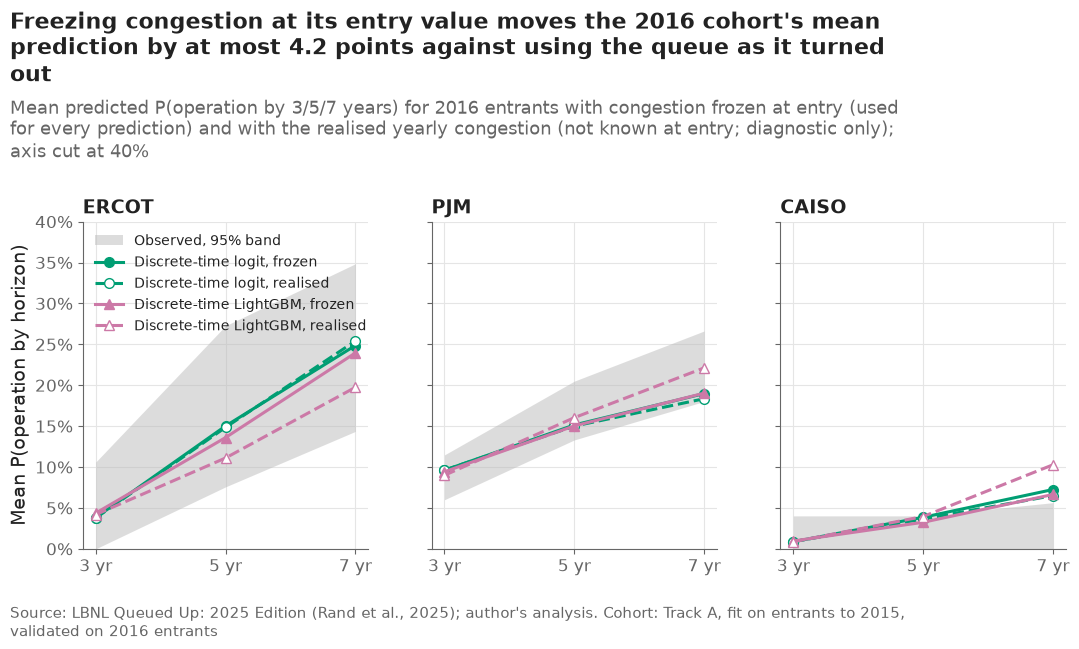

,region,horizon,dt_logit,dt_logit_realised,dt_lgbm,dt_lgbm_realised
0,ERCOT,3,0.038,0.038,0.044,0.042
1,ERCOT,5,0.150,0.148,0.136,0.111
2,ERCOT,7,0.249,0.254,0.239,0.197
3,PJM,3,0.096,0.096,0.094,0.090
4,PJM,5,0.151,0.150,0.150,0.160
5,PJM,7,0.190,0.184,0.190,0.221
6,CAISO,3,0.009,0.009,0.010,0.009
7,CAISO,5,0.039,0.036,0.032,0.039
8,CAISO,7,0.072,0.065,0.066,0.103


In [11]:
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    for model in ["dt_logit", "dt_lgbm"]:
        style = MODEL_STYLE[model]
        ax.plot(part["horizon"], part[model], color=style["color"], marker=style["marker"],
                label=f"{MODEL_LABELS[model]}, frozen")
        ax.plot(part["horizon"], part[f"{model}_realised"], color=style["color"], marker=style["marker"],
                markerfacecolor="white", linestyle="--", label=f"{MODEL_LABELS[model]}, realised")
    ax.set_title(region)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.4)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
shift = 100 * pd.concat([(validation[f"{m}_realised"] - validation[m]).abs() for m in ["dt_logit", "dt_lgbm"]]).max()
print(f"largest change, frozen vs realised congestion: {shift:.1f} points")
plots.finish(fig,
             f"Freezing congestion at its entry value moves the 2016 cohort's mean prediction by at most {shift:.1f} points "
             f"against using the queue as it turned out",
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants with congestion frozen at entry (used for every "
             "prediction) and with the realised yearly congestion (not known at entry; diagnostic only); axis cut at 40%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "06_08_frozen_vs_realised_congestion", "Effect of freezing congestion at its entry value on the 2016 cohort's mean predictions.")
plt.show()
validation[["region", "horizon", "dt_logit", "dt_logit_realised", "dt_lgbm", "dt_lgbm_realised"]].round(3)

**Reading this.** Set against what happened to the 2016 entrants, both discrete-time models are closer on average than notebook 05's models: mean absolute error over the nine region × horizon cells is 1.8 points for the logit and 1.7 for LightGBM, against 2.6 for the baseline and 3.9 for Cox. In ERCOT the logit hits the 7-year level exactly (24.9% predicted, 24.2% observed) where Cox predicted 15.5%. CAISO is the shared failure: its 2016 entrants reached operation only 2.4% of the time by year 7, below the band of every model (baseline 7.6%, Cox 8.5%, logit 7.2%, LightGBM 6.6%). Freezing congestion at entry, as every real prediction must, is not a handicap: with the realised yearly congestion the errors would be 1.9 and 2.5 points, i.e. no better, and the largest shift between the two versions is 4.2 points (LightGBM, ERCOT, 7 years: 23.9% frozen vs 19.7% realised). LightGBM is the more sensitive model because it uses yearly congestion more.

## 8. The final models and what they say

Both models are refitted on entrants up to 2016 with the chosen settings
(LightGBM for the early-stopping round count). The logit's coefficients are
odds ratios against staying in the queue for one more year; with the early
interactions each attribute has one odds ratio for years 1–3 and one for
years 4–10. Intervals come from 200 bootstrap resamples of projects.

In [12]:
final_enc = discrete_time.encode_state(rows_final)[0]
X_final = discrete_time.logit_design(final_enc, INTERACTIONS)
logit_final = discrete_time.fit_logit(X_final, final_enc["outcome"], LOGIT_BEST_C)
lgbm_final = discrete_time.fit_lgbm(discrete_time.lgbm_design(final_enc), final_enc["outcome"], LGBM_PARAMS, N_ROUNDS)


def log_odds(model, columns):
    """Per-unit log odds of operation and of withdrawal against staying, from a fitted pipeline."""
    scale = model[0].scale_
    coef = model[-1].coef_ / scale  # back from standardised to original units
    return pd.DataFrame({"operation": coef[1] - coef[0], "withdrawal": coef[2] - coef[0]}, index=columns)


point = log_odds(logit_final, X_final.columns)
rng = np.random.default_rng(6)
projects = final_enc["project"].unique()
row_groups = final_enc.groupby("project").indices
draws = []
for _ in range(200):
    pick = np.concatenate([row_groups[p] for p in rng.choice(projects, len(projects))])
    model = discrete_time.fit_logit(X_final.iloc[pick], final_enc["outcome"].iloc[pick], LOGIT_BEST_C)
    draws.append(log_odds(model, X_final.columns))
draws = np.stack([d.to_numpy() for d in draws])

ATTRIBUTES = {"region_CAISO": "CAISO (vs PJM)", "region_ERCOT": "ERCOT (vs PJM)",
              "tech_Solar+Battery": "Solar+Battery (vs Solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
              "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
              "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
              "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
              "service_missing": "Service missing", "log_mw": "log MW (+1)",
              "q_year": "Request year (+1)", "log_congestion_gw": "log(1 + GW waiting) (+1)",
              "congestion_rank": "Congestion rank at entry (0 → 1)", "state_operation": "State operation rate (+1 point)",
              "state_withdrawal": "State withdrawal rate (+1 point)"}
or_rows = []
for column, label in ATTRIBUTES.items():
    unit = 0.01 if column.startswith("state_") else 1.0
    early_column = f"early × {column}"
    j = list(X_final.columns).index(column)
    k = list(X_final.columns).index(early_column) if early_column in X_final.columns else None
    for cause_i, cause in enumerate(["operation", "withdrawal"]):
        for period in ["years 4–10", "years 1–3"]:
            if period == "years 1–3" and k is None:
                continue
            value = point.iloc[j][cause] + (point.iloc[k][cause] if period == "years 1–3" else 0)
            sample = draws[:, j, cause_i] + (draws[:, k, cause_i] if period == "years 1–3" else 0)
            or_rows.append({"attribute": column, "label": label, "cause": cause, "period": period,
                            "odds_ratio": np.exp(unit * value), "ci_low": np.exp(unit * np.quantile(sample, 0.025)),
                            "ci_high": np.exp(unit * np.quantile(sample, 0.975))})
odds = pd.DataFrame(or_rows)
odds.to_csv(paths.RESULTS / "dt_logit_odds_ratios.csv", index=False)
odds.pivot_table(index="label", columns=["cause", "period"], values="odds_ratio", sort=False).round(2)

cause                             operation           withdrawal          
period                           years 4–10 years 1–3 years 4–10 years 1–3
label                                                                     
CAISO (vs PJM)                         1.11      0.39       0.64      1.26
ERCOT (vs PJM)                         1.34       NaN       0.56       NaN
Solar+Battery (vs Solar)               0.23      2.59       0.14      0.16
Wind                                   0.47      1.08       1.32      0.74
Offshore wind                          0.11      0.03       0.70      0.81
Battery                                0.41      0.87       0.70      0.87
Gas                                    2.04      5.48       1.09      0.72
Other technology                       0.93      3.48       0.91      0.85
< 5 MW (vs 20–100 MW)                  0.67      2.76       2.07      0.99
5–20 MW                                1.00      1.56       1.44      1.02
100–200 MW                             0.94      0.27       0.83      0.91
200–500 MW                             0.71      0.15       0.97      1.19
≥ 500 MW                               0.51      0.06       1.12      1.54
ERIS (vs NRIS)                         0.73       NaN       1.01       NaN
Service missing                        1.20       NaN       1.67       NaN
log MW (+1)                            0.91       NaN       1.00       NaN
Request year (+1)                      0.94       NaN       1.01       NaN
log(1 + GW waiting) (+1)               1.10       NaN       1.28       NaN
Congestion rank at entry (0 → 1)       0.41       NaN       0.60       NaN
State operation rate (+1 point)        1.14       NaN       1.01       NaN
State withdrawal rate (+1 point)       1.00       NaN       1.06       NaN

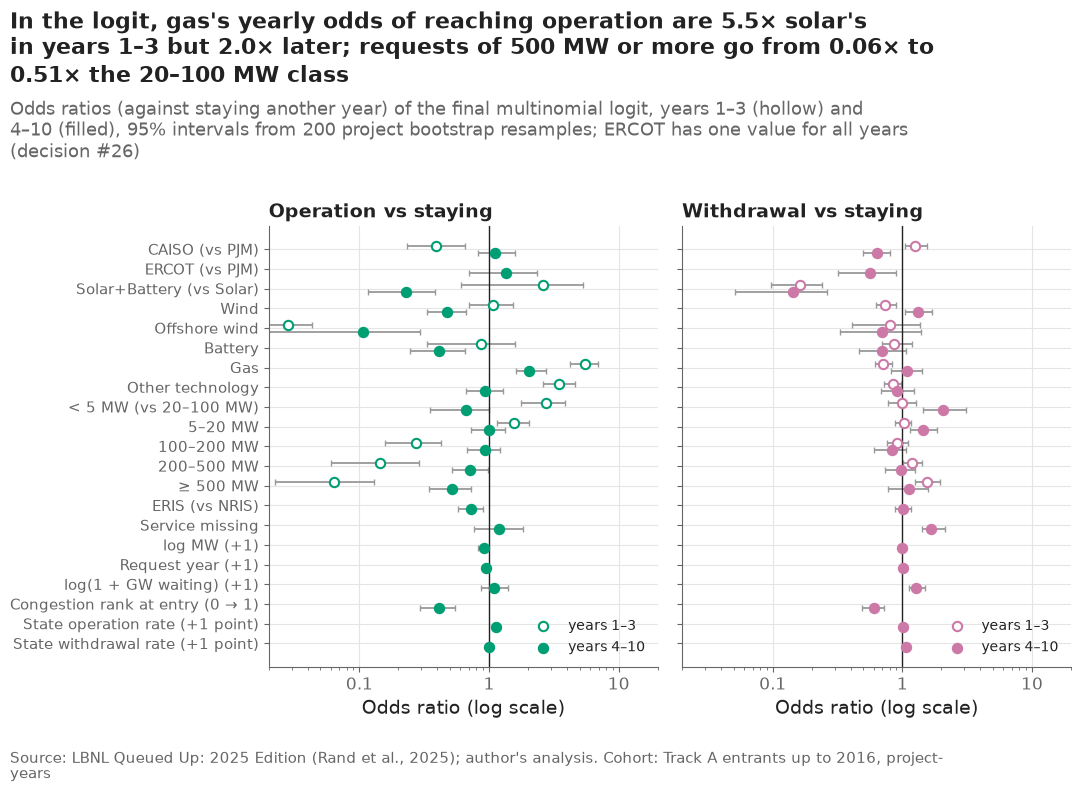

In [13]:
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 8))
labels = list(ATTRIBUTES.values())
y_pos = {label: len(labels) - 1 - i for i, label in enumerate(labels)}
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    for period, offset, face in [("years 1–3", 0.18, "white"), ("years 4–10", -0.18, config.OUTCOME_COLORS[cause])]:
        part = odds[(odds["cause"] == cause) & (odds["period"] == period)]
        y = part["label"].map(y_pos) + offset
        ax.errorbar(part["odds_ratio"], y, xerr=[part["odds_ratio"] - part["ci_low"], part["ci_high"] - part["odds_ratio"]],
                    fmt="none", color="#999999", linewidth=1.3, capsize=2)
        ax.scatter(part["odds_ratio"], y, s=45, zorder=3, color=face, edgecolors=config.OUTCOME_COLORS[cause],
                   linewidths=1.5, label=period)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.02, 20)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()} vs staying")
    ax.set_xlabel("Odds ratio (log scale)")
    ax.legend(loc="lower right", fontsize=10)
axes[0].set_yticks(list(y_pos.values()), list(y_pos.keys()), fontsize=10.5)
op = odds[odds["cause"] == "operation"].set_index(["attribute", "period"])["odds_ratio"]
plots.finish(fig,
             f"In the logit, gas's yearly odds of reaching operation are {op[('tech_Gas', 'years 1–3')]:.1f}× solar's in years "
             f"1–3 but {op[('tech_Gas', 'years 4–10')]:.1f}× later; requests of 500 MW or more go from "
             f"{op[('size_≥500', 'years 1–3')]:.2f}× to {op[('size_≥500', 'years 4–10')]:.2f}× the 20–100 MW class",
             "Odds ratios (against staying another year) of the final multinomial logit, years 1–3 (hollow) and 4–10 "
             "(filled), 95% intervals from 200 project bootstrap resamples; ERCOT has one value for all years (decision #26)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, project-years")
save(fig, "06_09_logit_odds_ratios", "Odds ratios of the final multinomial logit for operation and withdrawal, early and late years in the queue.")
plt.show()

**Reading this.** The logit's odds ratios confirm and sharpen notebook 05's hazard ratios. The fast profiles are fast early: gas's yearly odds of reaching operation are 5.48× solar's in years 1–3 and 2.04× afterwards; requests under 5 MW 2.76× the 20–100 MW class early and 0.67× later; requests of 500 MW or more 0.06× early and 0.51× later. CAISO's disadvantage is all early (0.39× PJM in years 1–3, 1.11× afterwards), and CAISO requests are more likely to withdraw early (1.26×) and less likely later (0.64×). ERCOT, with one value for all years, has 1.34× PJM's odds of operating and 0.56× its odds of withdrawing (Cox: 1.66× for operation). More GW waiting in a given year raises the odds of withdrawing (1.28× per log unit) more than those of operating (1.10×), and a request that entered a queue crowded relative to its region's history has lower odds of both (0.41× and 0.60×). Solar+Battery's early value (2.59×) rests on few early completions and its interval in the figure is wide; it should not be read as a finding.

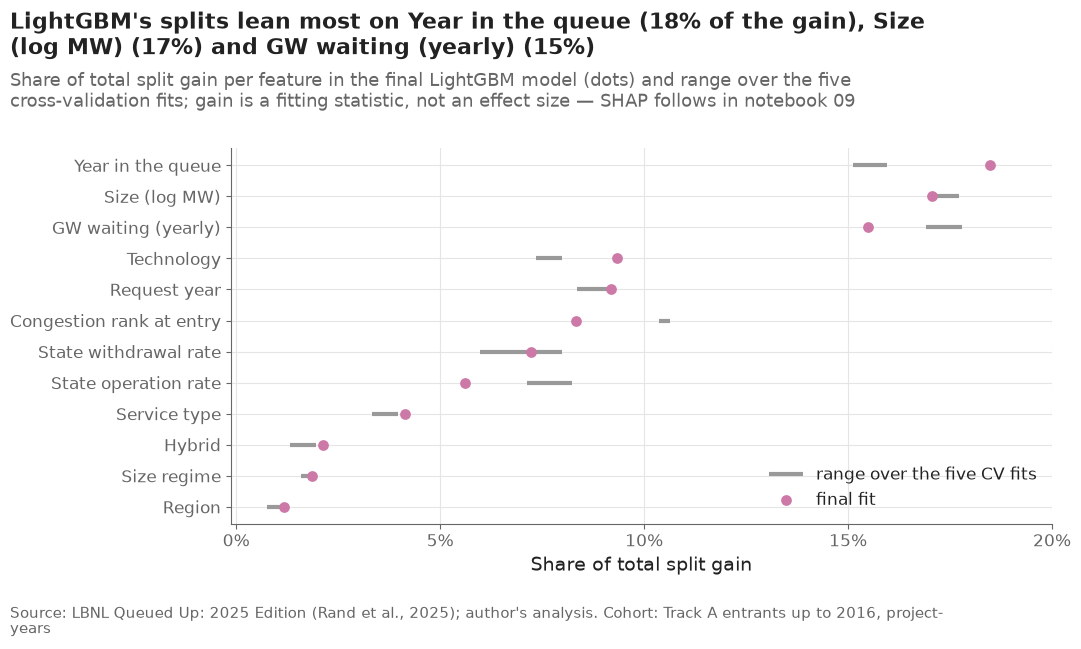

,fold 0,fold 1,fold 2,fold 3,fold 4,final
year_in_queue,0.156,0.158,0.160,0.158,0.151,0.185
log_mw,0.175,0.173,0.171,0.177,0.173,0.171
log_congestion_gw,0.173,0.178,0.169,0.172,0.177,0.155
tech,0.077,0.076,0.074,0.074,0.080,0.093
q_year,0.084,0.092,0.093,0.089,0.089,0.092
congestion_rank,0.104,0.104,0.105,0.104,0.106,0.083
state_withdrawal,0.080,0.070,0.071,0.068,0.060,0.072
state_operation,0.074,0.076,0.071,0.078,0.082,0.056
service,0.033,0.035,0.040,0.036,0.038,0.041
hybrid,0.020,0.013,0.019,0.019,0.018,0.021


In [14]:
importance_rows = []
names = list(discrete_time.lgbm_design(fold_data[0][0].iloc[:5]).columns)
for i in range(len(folds)):
    gains = boosters[((LGBM_PARAMS["num_leaves"], LGBM_PARAMS["min_data_in_leaf"]), i)].feature_importance(
        "gain", iteration=CHOSEN_CV_ROUNDS)
    importance_rows.append(pd.Series(gains / gains.sum(), index=names, name=f"fold {i}"))
importance = pd.concat(importance_rows, axis=1)
final_gain = lgbm_final.feature_importance("gain")
importance["final"] = final_gain / final_gain.sum()
importance = importance.sort_values("final")
importance.to_csv(paths.RESULTS / "dt_lgbm_importance.csv")
FEATURE_LABELS = {"year_in_queue": "Year in the queue", "region": "Region", "tech": "Technology", "size_regime": "Size regime",
                  "service": "Service type", "hybrid": "Hybrid", "log_mw": "Size (log MW)", "q_year": "Request year",
                  "log_congestion_gw": "GW waiting (yearly)", "congestion_rank": "Congestion rank at entry",
                  "state_operation": "State operation rate", "state_withdrawal": "State withdrawal rate"}

fig, ax = plt.subplots()
fold_cols = [c for c in importance.columns if c.startswith("fold")]
y = np.arange(len(importance))
ax.hlines(y, importance[fold_cols].min(axis=1), importance[fold_cols].max(axis=1), color="#999999", linewidth=3,
          label="range over the five CV fits")
ax.scatter(importance["final"], y, color=MODEL_STYLE["dt_lgbm"]["color"], s=60, zorder=3, label="final fit")
ax.set_yticks(y, [FEATURE_LABELS[f] for f in importance.index])
ax.set_xticks(np.arange(0, importance.to_numpy().max() + 0.05, 0.05))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of total split gain")
ax.legend(loc="lower right")
top = importance["final"].sort_values(ascending=False)
plots.finish(fig,
             f"LightGBM's splits lean most on {FEATURE_LABELS[top.index[0]]} ({top.iloc[0]:.0%} of the gain), "
             f"{FEATURE_LABELS[top.index[1]]} ({top.iloc[1]:.0%}) and {FEATURE_LABELS[top.index[2]]} "
             f"({top.iloc[2]:.0%})",
             "Share of total split gain per feature in the final LightGBM model (dots) and range over the five "
             "cross-validation fits; gain is a fitting statistic, not an effect size — SHAP follows in notebook 09",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, project-years")
save(fig, "06_10_lgbm_importance", "Split-gain importance of each feature in the LightGBM hazard model.")
plt.show()
importance.round(3).iloc[::-1]

**Reading this.** LightGBM's splits use the year in the queue most (18.5% of the gain in the final fit), then size (17.1%) and the yearly GW waiting (15.5%); region carries only 1.2%. That does not mean region does not matter: the state rates, congestion and technology mix already differ by region, so the trees reach regional differences through them. The five cross-validation fits give similar shares (e.g. size 17.1–17.7%), so the ranking is stable. Gain says where the trees split, not how much a feature moves a prediction; SHAP in notebook 09 answers that.

### Year-in-queue profiles for a reference request

The yearly hazards each model gives one reference request — solar,
20–100 MW (50 MW), NRIS, not hybrid, requested in 2016 at its region's
median congestion, in its region's most common state — by region; then the
operation hazard for the same request in PJM with each technology. The
second view shows whether the models let technologies differ in *when* they
reach operation, not only in how often.

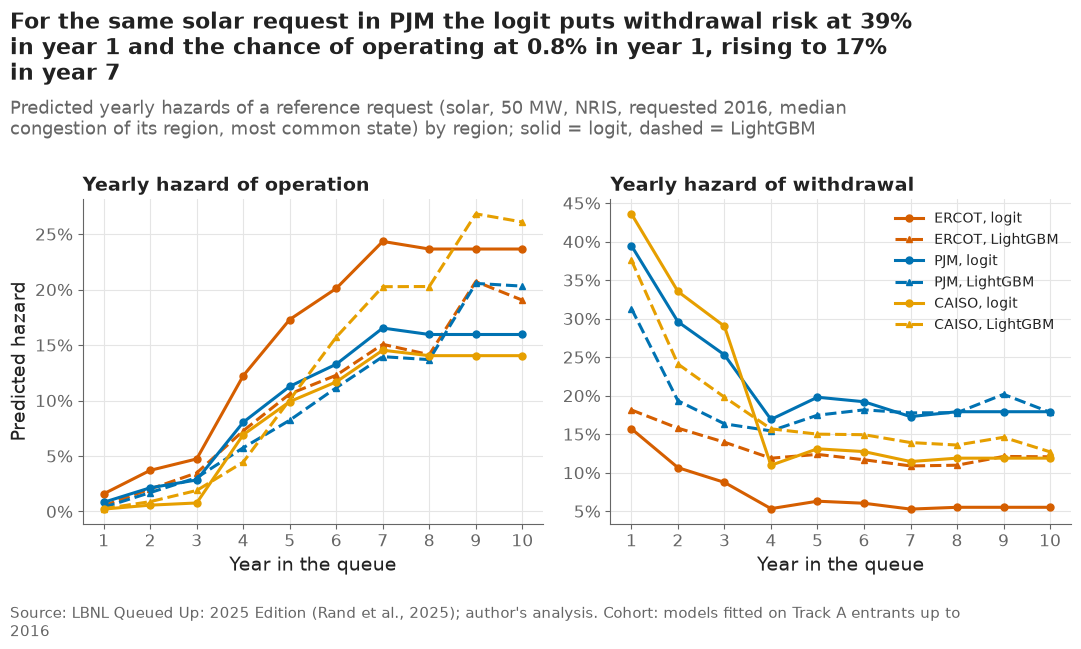

,dt_logit operation ERCOT,dt_logit operation PJM,dt_logit operation CAISO,dt_logit withdrawal ERCOT,dt_logit withdrawal PJM,dt_logit withdrawal CAISO,dt_lgbm operation ERCOT,dt_lgbm operation PJM,dt_lgbm operation CAISO,dt_lgbm withdrawal ERCOT,dt_lgbm withdrawal PJM,dt_lgbm withdrawal CAISO
year_in_queue,,,,,,,,,,,,
1,0.016,0.008,0.002,0.157,0.395,0.436,0.005,0.004,0.002,0.181,0.313,0.376
2,0.037,0.021,0.006,0.107,0.296,0.335,0.020,0.017,0.009,0.158,0.193,0.241
3,0.047,0.028,0.008,0.087,0.253,0.290,0.035,0.030,0.019,0.140,0.163,0.198
4,0.122,0.080,0.069,0.053,0.169,0.110,0.073,0.057,0.044,0.119,0.154,0.157
5,0.173,0.113,0.099,0.063,0.198,0.131,0.106,0.082,0.101,0.124,0.175,0.150
6,0.201,0.133,0.117,0.060,0.192,0.127,0.123,0.112,0.157,0.117,0.182,0.149
7,0.243,0.165,0.145,0.053,0.173,0.114,0.151,0.140,0.203,0.109,0.178,0.139
8,0.237,0.160,0.140,0.055,0.179,0.119,0.141,0.137,0.203,0.110,0.178,0.136
9,0.237,0.160,0.140,0.055,0.179,0.119,0.207,0.206,0.268,0.121,0.202,0.146


In [15]:
def reference(region, tech="Solar", n=1):
    """A synthetic reference request in `region` (entry-time features only)."""
    part = final[final["region"] == region]
    return pd.DataFrame([{"region": region, "tech": tech, "size_regime": "20–<100", "service": "NRIS", "hybrid": False,
                          "log_mw": np.log(50), "q_year": 2016, "q_date": pd.Timestamp("2016-07-01"),
                          "congestion_gw": part["congestion_gw"].median(), "congestion_rank": part["congestion_rank"].median(),
                          "state": part["state"].mode().iloc[0]}] * n, index=[f"{region}|{tech}"] * n)


def hazards_of(frame):
    """Yearly hazards (operation, withdrawal) of both final models for each request of `frame`, years 1–10."""
    rows = discrete_time.prediction_rows(frame)
    _, rows = discrete_time.encode_state(rows_final, [rows])
    out = {}
    for model, X in [("dt_logit", discrete_time.logit_design(rows, INTERACTIONS)), ("dt_lgbm", discrete_time.lgbm_design(rows))]:
        h_op, h_wd = discrete_time.predict_hazards(logit_final if model == "dt_logit" else lgbm_final, X)
        out[model] = (h_op.reshape(len(frame), -1), h_wd.reshape(len(frame), -1))
    return out


refs = pd.concat([reference(region) for region in TRACK_A])
ref_h = hazards_of(refs)
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, (cause_i, cause) in zip(axes, enumerate(["operation", "withdrawal"])):
    for r_i, region in enumerate(TRACK_A):
        for model, style in [("dt_logit", "-"), ("dt_lgbm", "--")]:
            ax.plot(YEARS, ref_h[model][cause_i][r_i], color=plots.region_color(region), linestyle=style,
                    marker="o" if model == "dt_logit" else "^", markersize=5,
                    label=f"{region}, {'logit' if model == 'dt_logit' else 'LightGBM'}")
    ax.set_title(f"Yearly hazard of {cause}")
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Predicted hazard")
axes[1].legend(loc="upper right", fontsize=10, ncol=1)
ref_table = pd.DataFrame({f"{model} {cause} {region}": ref_h[model][c_i][r_i]
                          for model in ["dt_logit", "dt_lgbm"] for c_i, cause in enumerate(["operation", "withdrawal"])
                          for r_i, region in enumerate(TRACK_A)}, index=YEARS)
ref_table.index.name = "year_in_queue"
ref_table.to_csv(paths.RESULTS / "dt_reference_request.csv")
pjm_i = TRACK_A.index("PJM")
plots.finish(fig,
             f"For the same solar request in PJM the logit puts withdrawal risk at {ref_h['dt_logit'][1][pjm_i][0]:.0%} in "
             f"year 1 and the chance of operating at {ref_h['dt_logit'][0][pjm_i][0]:.1%} in year 1, rising to "
             f"{ref_h['dt_logit'][0][pjm_i][6]:.0%} in year 7",
             "Predicted yearly hazards of a reference request (solar, 50 MW, NRIS, requested 2016, median congestion of its "
             "region, most common state) by region; solid = logit, dashed = LightGBM",
             f"models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_11_reference_hazards", "Predicted yearly hazards of operation and withdrawal for a reference solar request in each region, both models.")
plt.show()
ref_table.round(3)

LightGBM gas ÷ solar yearly operation hazard, years 1–10: [5.1, 5.5, 4.8, 3.7, 2.7, 2.2, 1.9, 1.9, 1.7, 1.7]


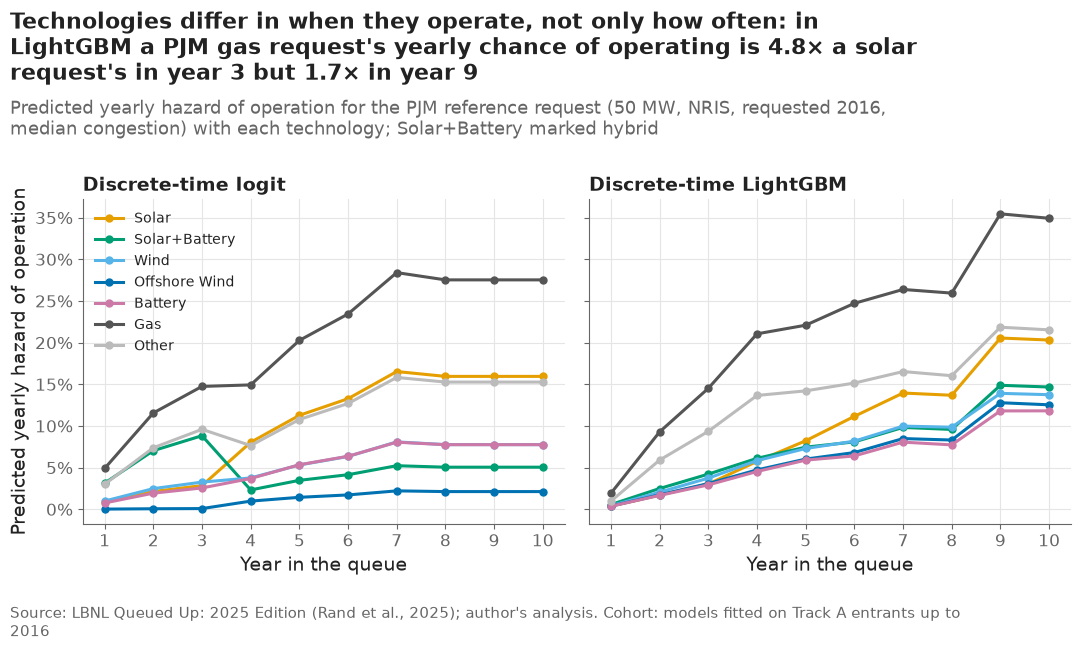

,dt_logit Solar,dt_logit Solar+Battery,dt_logit Wind,dt_logit Offshore Wind,dt_logit Battery,dt_logit Gas,dt_logit Other,dt_lgbm Solar,dt_lgbm Solar+Battery,dt_lgbm Wind,dt_lgbm Offshore Wind,dt_lgbm Battery,dt_lgbm Gas,dt_lgbm Other
1,0.008,0.031,0.010,0.000,0.008,0.049,0.030,0.004,0.006,0.004,0.004,0.004,0.019,0.010
2,0.021,0.070,0.025,0.001,0.019,0.116,0.074,0.017,0.025,0.021,0.017,0.017,0.093,0.059
3,0.028,0.088,0.033,0.001,0.026,0.147,0.096,0.030,0.042,0.037,0.031,0.029,0.145,0.094
4,0.080,0.023,0.038,0.010,0.037,0.149,0.076,0.057,0.061,0.058,0.047,0.045,0.211,0.137
5,0.113,0.035,0.053,0.014,0.053,0.203,0.108,0.082,0.075,0.073,0.060,0.059,0.221,0.142
6,0.133,0.042,0.063,0.017,0.064,0.234,0.127,0.112,0.081,0.082,0.068,0.064,0.247,0.152
7,0.165,0.052,0.081,0.022,0.081,0.284,0.158,0.140,0.098,0.100,0.085,0.081,0.264,0.165
8,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.137,0.096,0.099,0.083,0.077,0.259,0.160
9,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.206,0.149,0.139,0.128,0.118,0.355,0.219
10,0.160,0.051,0.078,0.021,0.078,0.275,0.153,0.203,0.147,0.138,0.125,0.118,0.349,0.215


In [16]:
techs = discrete_time.TECH_LEVELS
tech_refs = pd.concat([reference("PJM", tech) for tech in techs])
tech_refs["hybrid"] = tech_refs["tech"] == "Solar+Battery"
tech_h = hazards_of(tech_refs)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, model in zip(axes, ["dt_logit", "dt_lgbm"]):
    for t_i, tech in enumerate(techs):
        ax.plot(YEARS, tech_h[model][0][t_i], color=config.TECH_COLORS[tech], marker="o", markersize=5, label=tech)
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Predicted yearly hazard of operation")
axes[0].legend(loc="upper left", fontsize=10)
tech_table = pd.DataFrame({f"{model} {tech}": tech_h[model][0][t_i] for model in ["dt_logit", "dt_lgbm"]
                           for t_i, tech in enumerate(techs)}, index=YEARS)
gas, solar = (tech_h["dt_lgbm"][0][techs.index(t)] for t in ["Gas", "Solar"])
print("LightGBM gas ÷ solar yearly operation hazard, years 1–10:", np.round(gas / solar, 1).tolist())
plots.finish(fig,
             f"Technologies differ in when they operate, not only how often: in LightGBM a PJM gas request's yearly chance "
             f"of operating is {gas[2] / solar[2]:.1f}× a solar request's in year 3 but {gas[8] / solar[8]:.1f}× in year 9",
             "Predicted yearly hazard of operation for the PJM reference request (50 MW, NRIS, requested 2016, median "
             "congestion) with each technology; Solar+Battery marked hybrid",
             f"models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_12_technology_profiles", "Predicted yearly hazard of operation by year in the queue for each technology, PJM reference request, both models.")
plt.show()
tech_table.round(3)

**Reading this.** For the same 50 MW solar request, the logit puts PJM's yearly withdrawal risk at 39.5% in year 1 and its yearly chance of operating at 0.8% in year 1, rising to 16.5% in year 7; in ERCOT the operation hazard is higher in every year (1.6% in year 1, 24.3% in year 7) and the withdrawal risk lower (15.7% in year 1). LightGBM gives ERCOT and PJM nearly the same operation hazards (e.g. 15.1% and 14.0% in year 7), so the two models disagree on how much faster ERCOT is — unsurprising, since ERCOT's effect rests on 288 project-years. Across technologies, LightGBM lets the gas advantage fade smoothly: a PJM gas request's yearly hazard is 5.1× solar's in year 1, 4.8× in year 3, 2.2× in year 6 and 1.7× in year 9. The logit can only switch between a years 1–3 and a years 4–10 value, which shows as jumps at year 4 (Solar+Battery falls from 8.8% to 2.3%); that step is a property of the design, not of the data, and one reason to prefer the smoother LightGBM profile for timing.

## 9. Acceptance check: do the models reproduce the observed incidence?

PLAN.md §6: the model's P(operation by t), averaged by region, must lie
inside the Aalen–Johansen 95% bootstrap band. For PJM and CAISO the
comparison is made on the entrants the final models were fitted on (to 2016),
with the same estimator and 500 resamples as notebook 03 — not on notebook
03's all-years curves, which contain the 2017–2019 test outcomes. Each request
is predicted from its entry date with congestion frozen there, exactly as test
requests will be.

**ERCOT is checked on its 2016 entrants** (section 7: models fitted on
entrants to 2015, band from 500 resamples), not on all its entrants to 2016
(decision #28, Alan, 2026-10-04). Under delayed entry the models never see
ERCOT before 2018-08-29, so ERCOT's earlier entrants — most of whom had left
the queue by that day — cannot be reproduced by construction; the 2016
entrants are the ERCOT cohort closest to the regime the models learn from.
The rule was changed after the first run showed ERCOT's all-entrants averages
below the band; that result stays in the table and the figure, marked as
reported, not checked. The test
`tests/test_discrete_time.py::test_model_cif_inside_aj_bands` reads the rows
marked `counts`.

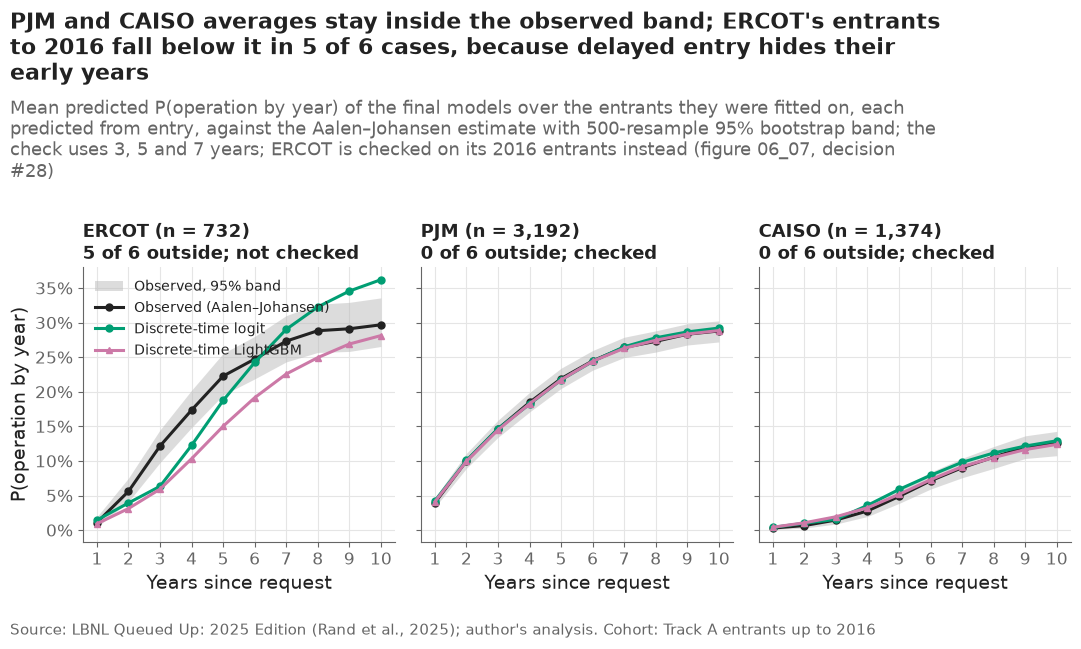

checked rows inside the band: 18 of 18


,region,cohort,counts,model,horizon,observed,band_low,band_high,predicted,inside
0,ERCOT,entrants to 2016 (final fit),False,dt_logit,3,0.122,0.098,0.145,0.063,False
1,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,3,0.122,0.098,0.145,0.059,False
2,ERCOT,entrants to 2016 (final fit),False,dt_logit,5,0.223,0.195,0.255,0.187,False
3,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,5,0.223,0.195,0.255,0.150,False
4,ERCOT,entrants to 2016 (final fit),False,dt_logit,7,0.273,0.243,0.310,0.290,True
5,ERCOT,entrants to 2016 (final fit),False,dt_lgbm,7,0.273,0.243,0.310,0.226,False
6,PJM,entrants to 2016 (final fit),True,dt_logit,3,0.146,0.134,0.159,0.147,True
7,PJM,entrants to 2016 (final fit),True,dt_lgbm,3,0.146,0.134,0.159,0.145,True
8,PJM,entrants to 2016 (final fit),True,dt_logit,5,0.219,0.205,0.234,0.217,True
9,PJM,entrants to 2016 (final fit),True,dt_lgbm,5,0.219,0.205,0.234,0.217,True


In [17]:
fit_pred = predict(final, rows_final, logit_final, lgbm_final, horizons=list(YEARS))
band_rows, curve_rows = [], []
for i, region in enumerate(TRACK_A):
    part = final[final["region"] == region]
    observed = survival_tools.aalen_johansen(part["duration_years"], part["event"], YEARS)
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], YEARS, n_boot=500, seed=600 + i)
    for j, year in enumerate(YEARS):
        entry = {"region": region, "n": len(part), "year": year, "observed": observed["cif_operation"].iloc[j],
                 "band_low": band["cif_operation_low"].iloc[j], "band_high": band["cif_operation_high"].iloc[j]}
        for model in ["dt_logit", "dt_lgbm"]:
            entry[model] = fit_pred[model].loc[part.index, year].mean()
        curve_rows.append(entry)
curves_fit = pd.DataFrame(curve_rows)
for _, row in curves_fit[curves_fit["year"].isin(HORIZONS)].iterrows():
    for model in ["dt_logit", "dt_lgbm"]:
        band_rows.append({"region": row["region"], "cohort": f"entrants to {config.TRAIN_MAX_YEAR} (final fit)",
                          "counts": row["region"] != "ERCOT", "model": model, "horizon": int(row["year"]),
                          "observed": row["observed"], "band_low": row["band_low"], "band_high": row["band_high"],
                          "predicted": row[model]})
for _, row in validation[validation["region"] == "ERCOT"].iterrows():  # decision #28
    for model in ["dt_logit", "dt_lgbm"]:
        band_rows.append({"region": "ERCOT", "cohort": f"{config.VALIDATION_YEAR} entrants (fit to {config.TUNE_MAX_YEAR})",
                          "counts": True, "model": model, "horizon": int(row["horizon"]), "observed": row["observed"],
                          "band_low": row["low"], "band_high": row["high"], "predicted": row[model]})
band_check = pd.DataFrame(band_rows)
band_check["inside"] = (band_check["band_low"] <= band_check["predicted"]) & (band_check["predicted"] <= band_check["band_high"])
counted = band_check[band_check["counts"]]
band_check.to_csv(paths.RESULTS / "dt_band_check.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = curves_fit[curves_fit["region"] == region]
    ax.fill_between(part["year"], part["band_low"], part["band_high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["year"], part["observed"], color=plots.INK, marker="o", markersize=5, label="Observed (Aalen–Johansen)")
    for model in ["dt_logit", "dt_lgbm"]:
        ax.plot(part["year"], part[model], label=MODEL_LABELS[model], **{**MODEL_STYLE[model], "markersize": 5})
    shown = band_check[(band_check["region"] == region) & band_check["cohort"].str.startswith("entrants")]
    status = "checked" if region != "ERCOT" else "not checked"
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})\n{int((~shown['inside']).sum())} of 6 outside; {status}", fontsize=13)
    ax.set_xlabel("Years since request")
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by year)")
axes[0].legend(loc="upper left", fontsize=10)
ercot_all = band_check[(band_check["region"] == "ERCOT") & ~band_check["counts"]]
pjm_caiso_inside = bool(counted.loc[counted["region"] != "ERCOT", "inside"].all())
plots.finish(fig,
             f"PJM and CAISO averages {'stay inside' if pjm_caiso_inside else 'do not all stay inside'} the observed band; "
             f"ERCOT's entrants to 2016 fall below it in {int((~ercot_all['inside']).sum())} of 6 cases, because delayed "
             "entry hides their early years",
             "Mean predicted P(operation by year) of the final models over the entrants they were fitted on, each predicted from "
             "entry, against the Aalen–Johansen estimate with 500-resample 95% bootstrap band; the check uses 3, 5 and 7 years; "
             "ERCOT is checked on its 2016 entrants instead (figure 06_07, decision #28)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_13_band_check", "Model-averaged P(operation by year) against the Aalen–Johansen estimate and bootstrap band, by region (acceptance check).")
plt.show()
print(f"checked rows inside the band: {int(counted['inside'].sum())} of {len(counted)}")
band_check.round(3)

Where the averages miss, the entry cohorts show why. The same comparison by
entry cohort, at 3 and 5 years (200 resamples per cohort band).

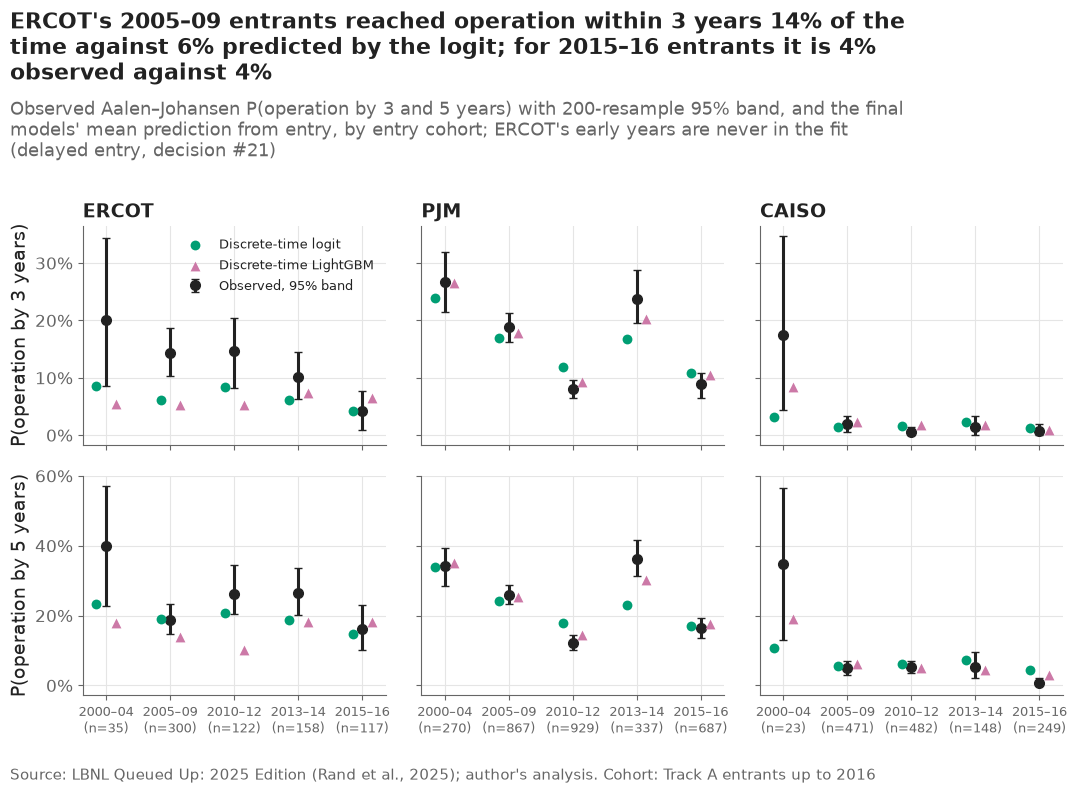

,region,cohort,n,horizon,observed,low,high,dt_logit,dt_lgbm
0,CAISO,2000–04,23,3,0.174,0.043,0.348,0.033,0.084
1,CAISO,2000–04,23,5,0.348,0.130,0.565,0.107,0.191
2,CAISO,2005–09,471,3,0.019,0.006,0.034,0.014,0.023
3,CAISO,2005–09,471,5,0.049,0.030,0.070,0.055,0.060
4,CAISO,2010–12,482,3,0.006,0.000,0.015,0.015,0.019
5,CAISO,2010–12,482,5,0.054,0.035,0.071,0.062,0.050
6,CAISO,2013–14,148,3,0.014,0.000,0.034,0.023,0.018
7,CAISO,2013–14,148,5,0.054,0.020,0.095,0.072,0.045
8,CAISO,2015–16,249,3,0.008,0.000,0.020,0.013,0.009
9,CAISO,2015–16,249,5,0.008,0.000,0.020,0.045,0.030


In [18]:
cohort_bins = [1999, 2004, 2009, 2012, 2014, 2016]
cohort_labels = ["2000–04", "2005–09", "2010–12", "2013–14", "2015–16"]
cohorts = pd.cut(final["q_year"].astype(float), cohort_bins, labels=cohort_labels)
cohort_rows = []
for i, ((region, cohort), part) in enumerate(final.groupby([final["region"], cohorts], observed=True)):
    observed = survival_tools.aalen_johansen(part["duration_years"], part["event"], [3, 5])
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], [3, 5], n_boot=200, seed=700 + i)
    for j, h in enumerate([3, 5]):
        cohort_rows.append({"region": region, "cohort": cohort, "n": len(part), "horizon": h,
                            "observed": observed["cif_operation"].iloc[j], "low": band["cif_operation_low"].iloc[j],
                            "high": band["cif_operation_high"].iloc[j],
                            "dt_logit": fit_pred["dt_logit"].loc[part.index, h].mean(),
                            "dt_lgbm": fit_pred["dt_lgbm"].loc[part.index, h].mean()})
cohort_check = pd.DataFrame(cohort_rows)
cohort_check.to_csv(paths.RESULTS / "dt_cohort_check.csv", index=False)

fig, axes = plt.subplots(2, 3, sharey="row", figsize=(11, 8))
for row_i, h in enumerate([3, 5]):
    for ax, region in zip(axes[row_i], TRACK_A):
        part = cohort_check[(cohort_check["region"] == region) & (cohort_check["horizon"] == h)]
        x = np.arange(len(part))
        ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt="o", color=plots.INK, capsize=3, label="Observed, 95% band")
        for model, dx in [("dt_logit", -0.15), ("dt_lgbm", 0.15)]:
            style = MODEL_STYLE[model]
            ax.scatter(x + dx, part[model], color=style["color"], marker=style["marker"], s=50, zorder=3,
                       label=MODEL_LABELS[model])
        ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(part["cohort"], part["n"])] if row_i == 1 else [], fontsize=9)
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
        if row_i == 0:
            ax.set_title(region)
    axes[row_i, 0].set_ylabel(f"P(operation by {h} years)")
axes[0, 0].legend(loc="upper right", fontsize=9.5)
ercot3 = cohort_check[(cohort_check["region"] == "ERCOT") & (cohort_check["horizon"] == 3)].set_index("cohort")
plots.finish(fig,
             f"ERCOT's 2005–09 entrants reached operation within 3 years {ercot3.loc['2005–09', 'observed']:.0%} of the "
             f"time against {ercot3.loc['2005–09', 'dt_logit']:.0%} predicted by the logit; for 2015–16 entrants it is "
             f"{ercot3.loc['2015–16', 'observed']:.0%} observed against {ercot3.loc['2015–16', 'dt_logit']:.0%}",
             "Observed Aalen–Johansen P(operation by 3 and 5 years) with 200-resample 95% band, and the final models' mean "
             "prediction from entry, by entry cohort; ERCOT's early years are never in the fit (delayed entry, decision #21)",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "06_14_cohort_check", "Observed versus predicted P(operation by 3 and 5 years) by entry cohort and region.")
plt.show()
cohort_check.round(3)

**Reading this.** With the check as decided (decision #28), it passes for both models. In PJM and CAISO the mean P(operation by 3, 5 and 7 years) over all entrants to 2016 lies inside the observed 95% band (e.g. PJM at 5 years: 21.7% for both models against 21.9% observed); for ERCOT's 2016 entrants, predicted by models that never saw them, both models are inside the band at every horizon (section 7: logit 3.8%, 15.0%, 24.9%; LightGBM 4.4%, 13.6%, 23.9%; observed 4.5%, 16.7%, 24.2%). That ERCOT check is weak: the 2016 cohort has only 66 ERCOT requests, so its band is wide (0–10.6% at 3 years, 14.4–34.8% at 7), and passing it shows the models are not far off, not that they are right. The ERCOT rule was changed after the first run, and the result it replaced is kept: over all ERCOT entrants to 2016, 5 of 6 values are below the band — the logit predicts 6.3% by year 3 against 12.2% observed (band 9.8–14.5%) and 18.7% by year 5 against 22.3%, LightGBM 5.9%, 15.0% and 22.6%. The cohort view shows why: ERCOT's 2005–09 entrants reached operation within 3 years 14.3% of the time against 6.1% (logit) and 5.3% (LightGBM) predicted, its 2010–12 entrants 14.8% against 8.4% and 5.3%, but its 2015–16 entrants 4.3% against 4.3% and 6.5%. Those earlier entrants finished fast in years delayed entry never shows the models (decision #21), so the models describe ERCOT as it behaved after 2018 — the regime the 2017–2019 test entrants face. That is a limitation for the report, and the reason the ERCOT sensitivity runs in notebook 08 matter. PJM's cohorts show what no entry-time model can capture: 2013–14 entrants did far better than predicted (23.7% by 3 years against 16.8% and 20.3%) and 2010–12 entrants worse (8.1% against 11.8% and 9.3%), offsetting in the regional average.

## 10. Predictions for the validation and test cohorts

Final models, every validation and test request predicted from its entry
date with congestion frozen there. They are merged with the baseline and Cox
predictions of notebook 05 into one long table (one row per request ×
horizon) in `data/processed/`. The observed event and duration are carried
along for notebook 08; nothing below summarises them.

In [19]:
targets = pd.concat([valid, test])
target_pred = predict(targets, rows_final, logit_final, lgbm_final)
pred05 = pd.read_parquet(paths.DATA_INTERIM / "predictions_05.parquet")
assert pred05.index.equals(targets.index), "notebook 05 predicted a different set of requests"
long_rows = []
for h in HORIZONS:
    long_rows.append(pd.DataFrame({
        "project_key": targets["project_key"].astype(str), "region": targets["region"].astype(str),
        "q_year": targets["q_year"].astype(int), "split": pred05["split"], "horizon": h,
        "baseline": pred05[f"baseline_{h}"], "baseline_cell": pred05["baseline_cell"], "cox": pred05[f"cox_{h}"],
        "dt_logit": target_pred["dt_logit"][h], "dt_lgbm": target_pred["dt_lgbm"][h],
        "dt_logit_expected_years": target_pred["dt_logit"]["expected_years"],
        "dt_lgbm_expected_years": target_pred["dt_lgbm"]["expected_years"],
        "event": targets["event"], "duration_years": targets["duration_years"],
        "entry_years": targets["entry_years"], "wd_bulk_date": targets["wd_bulk_date"].astype(bool)}))
predictions = pd.concat(long_rows, ignore_index=True)
out_file = paths.DATA_PROCESSED / "predictions_trackA.parquet"
predictions.to_parquet(out_file, index=False)
print(f"{out_file.name}: {len(predictions):,} rows ({predictions['project_key'].nunique():,} requests × {len(HORIZONS)} horizons), "
      f"{out_file.stat().st_size / 1e6:.2f} MB")
predictions.groupby(["split", "region", "horizon"])[["baseline", "cox", "dt_logit", "dt_lgbm"]].mean().round(3)

predictions_trackA.parquet: 8,523 rows (2,841 requests × 3 horizons), 0.32 MB


baseline    cox  dt_logit  dt_lgbm
split      region horizon                                    
test       CAISO  3           0.008  0.023     0.008    0.012
                  5           0.021  0.042     0.026    0.036
                  7           0.053  0.064     0.050    0.073
           ERCOT  3           0.090  0.095     0.060    0.080
                  5           0.183  0.153     0.164    0.176
                  7           0.230  0.196     0.244    0.250
           PJM    3           0.100  0.068     0.061    0.077
                  5           0.159  0.114     0.112    0.145
                  7           0.203  0.154     0.156    0.204
validation CAISO  3           0.007  0.033     0.009    0.008
                  5           0.032  0.061     0.040    0.027
                  7           0.072  0.089     0.073    0.053
           ERCOT  3           0.100  0.076     0.036    0.062
                  5           0.197  0.126     0.139    0.182
                  7           0.245  0.167     0.224    0.296
           PJM    3           0.111  0.093     0.097    0.091
                  5           0.176  0.154     0.162    0.158
                  7           0.223  0.200     0.211    0.207

distinct baseline values per region: {'CAISO': 7, 'ERCOT': 4, 'PJM': 6}


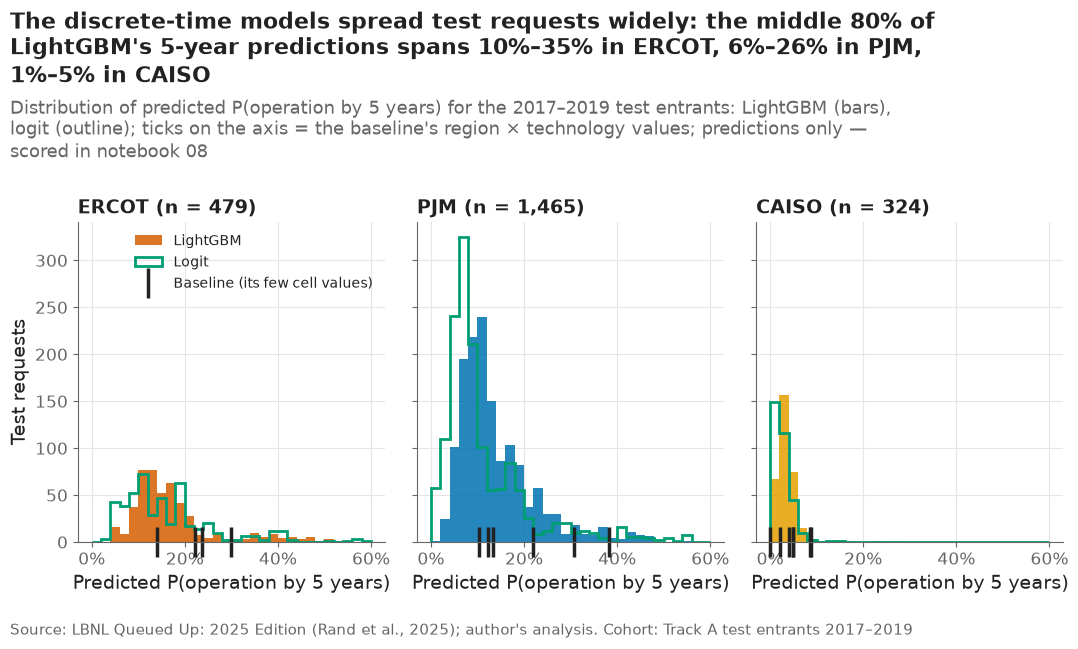

dt_logit        dt_lgbm       
            0.1    0.9     0.1    0.9
region                               
CAISO     0.009  0.051   0.015  0.053
ERCOT     0.061  0.320   0.096  0.345
PJM       0.037  0.212   0.062  0.256

In [20]:
test_pred = predictions[(predictions["split"] == "test") & (predictions["horizon"] == 5)]
fig, axes = plt.subplots(1, 3, sharey=True)
bins = np.linspace(0, 0.6, 31)
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.hist(part["dt_lgbm"], bins=bins, color=plots.region_color(region), alpha=0.85, label="LightGBM")
    ax.hist(part["dt_logit"], bins=bins, histtype="step", color=MODEL_STYLE["dt_logit"]["color"], linewidth=2, label="Logit")
    cells = part["baseline"].round(4).unique()
    ax.plot(cells, np.zeros(len(cells)), linestyle="none", marker="|", markersize=22, markeredgewidth=2.5,
            color=plots.INK, label="Baseline (its few cell values)", clip_on=False)
    ax.set_title(f"{region} (n = {len(part):,})")
    ax.set_xlabel("Predicted P(operation by 5 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Test requests")
axes[0].legend(loc="upper right", fontsize=10)
print("distinct baseline values per region:", test_pred.groupby("region")["baseline"].nunique().to_dict())
spread = test_pred.groupby("region")[["dt_logit", "dt_lgbm"]].quantile([0.1, 0.9]).unstack()
plots.finish(fig,
             "The discrete-time models spread test requests widely: the middle 80% of LightGBM's 5-year predictions spans "
             + ", ".join(f"{spread.loc[r, ('dt_lgbm', 0.1)]:.0%}–{spread.loc[r, ('dt_lgbm', 0.9)]:.0%} in {r}" for r in TRACK_A),
             "Distribution of predicted P(operation by 5 years) for the 2017–2019 test entrants: LightGBM (bars), logit "
             "(outline); ticks on the axis = the baseline's region × technology values; predictions only — scored in notebook 08",
             "Track A test entrants 2017–2019")
save(fig, "06_15_test_prediction_spread", "Distribution of 5-year predictions for the test entrants: discrete-time models versus baseline.")
plt.show()
spread.round(3)

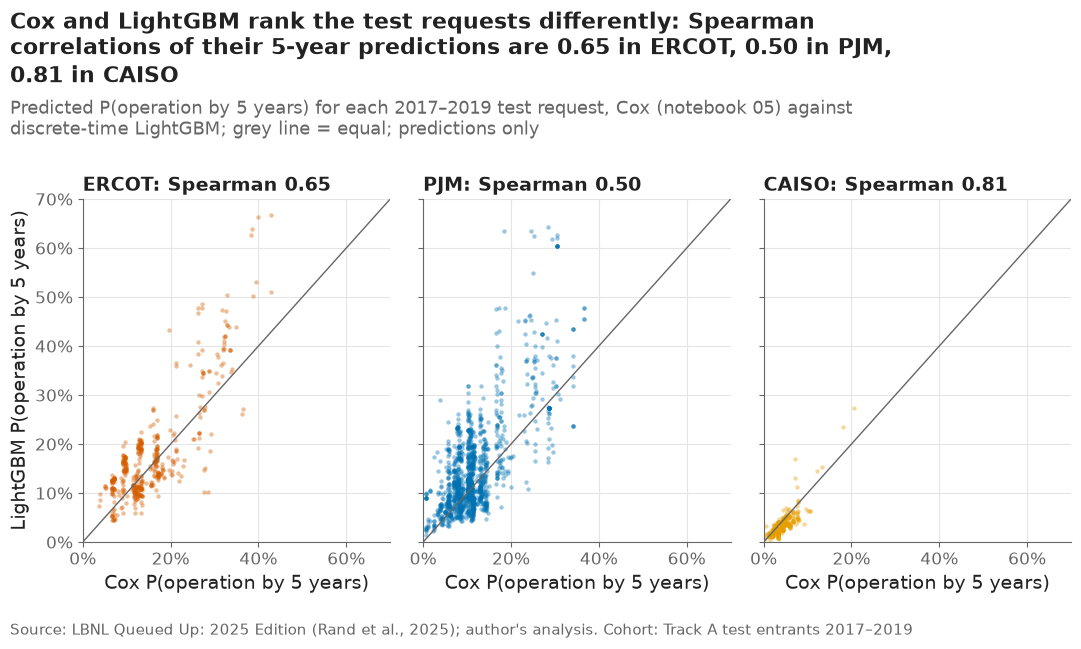

,dt_logit,dt_lgbm,dt_logit vs dt_lgbm
ERCOT,0.98,0.65,0.71
PJM,0.80,0.50,0.77
CAISO,0.95,0.81,0.81


In [21]:
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True)
agreement = {}
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.scatter(part["cox"], part["dt_lgbm"], s=10, alpha=0.4, color=plots.region_color(region), linewidths=0)
    ax.plot([0, 0.7], [0, 0.7], color=plots.MUTED, linewidth=1)
    ranks = part[["cox", "dt_logit", "dt_lgbm"]].corr(method="spearman")
    rho = {"dt_logit": ranks.loc["cox", "dt_logit"], "dt_lgbm": ranks.loc["cox", "dt_lgbm"],
           "dt_logit vs dt_lgbm": ranks.loc["dt_logit", "dt_lgbm"]}
    agreement[region] = rho
    ax.set_title(f"{region}: Spearman {rho['dt_lgbm']:.2f}")
    ax.set_xlabel("Cox P(operation by 5 years)")
    ax.set_xlim(0, 0.7)
    ax.set_ylim(0, 0.7)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("LightGBM P(operation by 5 years)")
agreement = pd.DataFrame(agreement).T
plots.finish(fig,
             "Cox and LightGBM rank the test requests differently: Spearman correlations of their 5-year predictions are "
             + ", ".join(f"{agreement.loc[r, 'dt_lgbm']:.2f} in {r}" for r in TRACK_A),
             "Predicted P(operation by 5 years) for each 2017–2019 test request, Cox (notebook 05) against discrete-time "
             "LightGBM; grey line = equal; predictions only",
             "Track A test entrants 2017–2019")
save(fig, "06_16_cox_vs_lgbm_test", "Cox versus discrete-time LightGBM 5-year predictions for each test request.")
plt.show()
agreement.round(2)

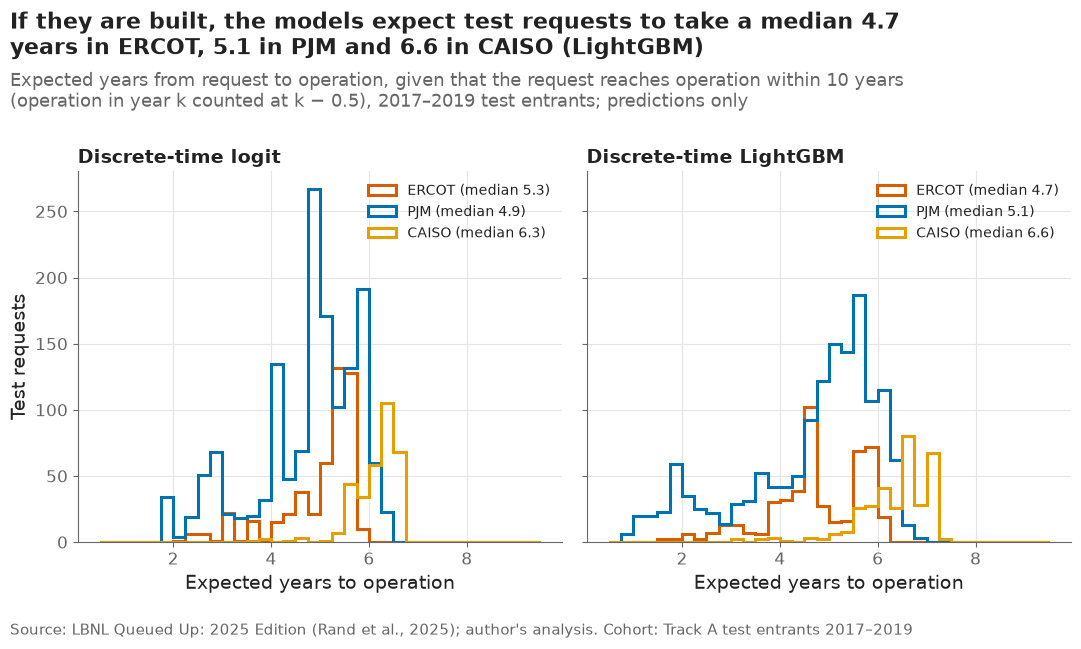

,dt_logit_expected_years,dt_lgbm_expected_years
region,,
CAISO,6.34,6.55
ERCOT,5.32,4.69
PJM,4.92,5.08


In [22]:
test_once = predictions[(predictions["split"] == "test") & (predictions["horizon"] == HORIZONS[0])]
fig, axes = plt.subplots(1, 2, sharey=True)
bins = np.linspace(0.5, 9.5, 37)
for ax, model in zip(axes, ["dt_logit", "dt_lgbm"]):
    for region in TRACK_A:
        values = test_once.loc[test_once["region"] == region, f"{model}_expected_years"]
        ax.hist(values, bins=bins, histtype="step", linewidth=2.2, color=plots.region_color(region),
                label=f"{region} (median {values.median():.1f})")
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Expected years to operation")
    ax.legend(loc="upper right", fontsize=10)
axes[0].set_ylabel("Test requests")
medians = test_once.groupby("region")[["dt_logit_expected_years", "dt_lgbm_expected_years"]].median()
plots.finish(fig,
             f"If they are built, the models expect test requests to take a median {medians.loc['ERCOT', 'dt_lgbm_expected_years']:.1f} "
             f"years in ERCOT, {medians.loc['PJM', 'dt_lgbm_expected_years']:.1f} in PJM and "
             f"{medians.loc['CAISO', 'dt_lgbm_expected_years']:.1f} in CAISO (LightGBM)",
             "Expected years from request to operation, given that the request reaches operation within 10 years (operation in "
             "year k counted at k − 0.5), 2017–2019 test entrants; predictions only",
             "Track A test entrants 2017–2019")
save(fig, "06_17_expected_time", "Distribution of the expected time to operation (among requests built within 10 years) for the test entrants.")
plt.show()
medians.round(2)

**Reading this.** Predictions for all 2,841 validation and test requests are in `data/processed/predictions_trackA.parquet` (8,523 rows, 0.32 MB) together with notebook 05's baseline and Cox values. On the test entrants the mean 5-year predictions of the four models are close in ERCOT (17.6% LightGBM, 16.4% logit, 15.3% Cox, 18.3% baseline) but differ in PJM (14.5%, 11.2%, 11.4%, 15.9%) — the logit and Cox, both linear in request year, project PJM's declining trend further than LightGBM, which cannot extrapolate. Within a region the discrete-time models spread requests widely (middle 80% of LightGBM's 5-year values: 9.6–34.5% in ERCOT, 6.2–25.6% in PJM, 1.5–5.3% in CAISO) where the baseline has only 4, 6 and 7 distinct values. LightGBM's ranking differs from Cox's (Spearman 0.65 in ERCOT, 0.50 in PJM, 0.81 in CAISO) while the logit's barely does (0.98, 0.80, 0.95), so LightGBM is the model that could change a developer's ordering of projects — whether for the better is notebook 08's question. If they are built, test requests are expected to take a median 4.7 years in ERCOT, 5.1 in PJM and 6.6 in CAISO (LightGBM; the logit gives 5.3, 4.9 and 6.3).

## 11. Checks

In [23]:
allowed = {"year_in_queue", "region", "tech", "size_regime", "service", "hybrid", "log_mw", "q_year",
           "log_congestion_gw", "congestion_rank", "state_operation", "state_withdrawal"}
lgbm_columns = set(discrete_time.lgbm_design(final_enc.iloc[:5]).columns)
cif_cols = [h for h in HORIZONS]
cif_ok = all(((p[cif_cols].diff(axis=1).iloc[:, 1:] >= -1e-12).all().all()
              and p[cif_cols].ge(0).all().all()
              and (p[HORIZONS[-1]] + p[f"withdrawal_{HORIZONS[-1]}"] <= 1 + 1e-9).all())
             for p in target_pred.values())
runtime = time.time() - START
checks = pd.DataFrame([
    ("predictions for every validation and test request at 3/5/7 years, all four models",
     len(predictions) == len(targets) * len(HORIZONS)
     and bool(predictions[["baseline", "cox", "dt_logit", "dt_lgbm"]].notna().all().all())),
    ("P(operation by t) within [0, 1], rising with t, operation + withdrawal ≤ 1", bool(cif_ok)),
    ("grouped folds: no project in both parts of a fold", overlap == 0),
    ("features are entry-time only (plus year in queue and yearly congestion)", lgbm_columns == allowed),
    ("logit: mean predicted P(operation by 3/5/7 yr) inside the Aalen–Johansen band in every region (ERCOT: 2016 entrants)",
     bool(counted.loc[counted["model"] == "dt_logit", "inside"].all())),
    ("LightGBM: mean predicted P(operation by 3/5/7 yr) inside the Aalen–Johansen band in every region (ERCOT: 2016 entrants)",
     bool(counted.loc[counted["model"] == "dt_lgbm", "inside"].all())),
    ("notebook runs in under 10 minutes", runtime < 600),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "dt_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 8.8 minutes


,check,result
0,predictions for every validation and test requ...,PASS
1,"P(operation by t) within [0, 1], rising with t...",PASS
2,grouped folds: no project in both parts of a fold,PASS
3,features are entry-time only (plus year in que...,PASS
4,logit: mean predicted P(operation by 3/5/7 yr)...,PASS
5,LightGBM: mean predicted P(operation by 3/5/7 ...,PASS
6,notebook runs in under 10 minutes,PASS


**Reading this.** All seven checks pass: complete predictions, valid probabilities, grouped folds without leakage, entry-time features only, the band check for both models (PJM and CAISO on the entrants to 2016, ERCOT on its 2016 entrants, decision #28) and a run time under 10 minutes (3–5 minutes on this laptop, depending on load). `pytest` runs the same band check in `test_model_cif_inside_aj_bands`.

## Takeaways

- The discrete-time models reproduce the observed incidence in PJM and CAISO at 3, 5 and 7 years and, on the 2016 cohort, are closer to what happened than the baseline and Cox (1.8 and 1.7 points mean error, against 2.6 and 3.9).
- ERCOT is checked on its 2016 entrants, where both models are inside the band (decision #28). Over all ERCOT entrants to 2016 they fall below it (5 of 6 values): earlier entrants completed fast in years delayed entry hides from the models — a limitation to state in the report.
- Effects change over the wait: gas is 5.48× solar's odds early and 2.04× later; very large requests 0.06× early and 0.51× later; CAISO's disadvantage is all in years 1–3.
- Grouped cross-validation rewarded ever larger trees that did worse on the later 2016 cohort (Spearman −0.65 between the two rankings); LightGBM was chosen on the 2016 cohort (8 leaves, 331 rounds; decision #27).
- Freezing congestion at entry costs nothing measurable on the 2016 cohort, although queues doubled within seven years of entry.

**What goes to the report:** 06_13 (band check) with 06_14 as the ERCOT explanation in the limitations; one sentence and 06_12 on how technology effects fade over the wait; the CV-versus-forward-validation finding (06_06) in the method section; predictions feed F4/F5 in notebook 08.